# Las Vegas & Phoenix: Full Weather × Energy Analysis

This notebook is a diagnostic study of the uploaded hourly weather and energy CSVs.

It is designed to answer two questions:

1. How are the weather variables related to one another?
2. How are weather variables related to electricity consumption?

The analysis includes data quality, coverage, distributions, Pearson and Spearman correlations, cross-parameter relationships, multicollinearity/VIF, mutual information, temporal conditioning, seasonal conditioning, temperature response curves, partial correlations after calendar controls, interaction diagnostics, and a Las Vegas versus Phoenix comparison.

The notebook does not modify the source CSV files.


In [7]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

print("Imports successful")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Imports successful
Pandas: 2.3.3
NumPy: 1.26.4


In [8]:
from pathlib import Path

BASE_DIR = Path.cwd()

FILES = {
    "Las Vegas": {
        "energy": BASE_DIR / "data" / "las_vegas_hourly_energy.csv",
        "weather": BASE_DIR / "data" / "las_vegas_hourly_weather_2016_2023.csv",
    },
    "Phoenix": {
        "energy": BASE_DIR / "data" / "phoenix_hourly_energy.csv",
        "weather": BASE_DIR / "data" / "phoenix_hourly_weather_2016_2023.csv",
    },
}

OUTPUT_DIR = BASE_DIR / "LV_Phoenix_Weather_Energy_Analysis"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

PLOT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE_DIR)

for city, paths in FILES.items():
    print(f"\n{city}")
    print("Energy:", paths["energy"], "exists:", paths["energy"].exists())
    print("Weather:", paths["weather"], "exists:", paths["weather"].exists())

Working directory: d:\Downloads\BTP\model_training\lstm_training_3

Las Vegas
Energy: d:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_energy.csv exists: True
Weather: d:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_weather_2016_2023.csv exists: True

Phoenix
Energy: d:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_energy.csv exists: True
Weather: d:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_weather_2016_2023.csv exists: True


## 2. Load and inspect the four CSV files

The notebook discovers timestamp and energy columns from the actual files instead of hard-coding assumptions.


In [9]:
def load_csv(path):
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")
    return pd.read_csv(path)

raw = {}

for city, paths in FILES.items():
    raw[city] = {
        "energy": load_csv(paths["energy"]),
        "weather": load_csv(paths["weather"]),
    }

for city, datasets in raw.items():
    print("\n" + "=" * 80)
    print(city)
    for kind, df in datasets.items():
        print(f"\n{kind.upper()} shape: {df.shape}")
        print("Columns:", df.columns.tolist())
        display(df.head(3))



Las Vegas

ENERGY shape: (70128, 2)
Columns: ['timestamp', 'hourly_load_mw']


,timestamp,hourly_load_mw
0,2016-01-01 00:00:00,2792.310974
1,2016-01-01 01:00:00,2975.455849
2,2016-01-01 02:00:00,3270.848686



WEATHER shape: (70080, 25)
Columns: ['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'timestamp']


,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,opaque_sky_cover_tenths,temperature_c,...,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm,timestamp
0,2016-01-01,1,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-1.1,...,24.1,10395.0,0,999999999,5.0,0.107,0.0,88.0,0.0,2016-01-01 00:00:00
1,2016-01-01,2,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-0.6,...,24.1,10395.0,0,999999999,5.0,0.107,0.0,88.0,0.0,2016-01-01 01:00:00
2,2016-01-01,3,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-1.7,...,24.1,10395.0,0,999999999,5.0,0.107,0.0,88.0,0.0,2016-01-01 02:00:00



Phoenix

ENERGY shape: (70128, 2)
Columns: ['timestamp', 'hourly_load_mw']


,timestamp,hourly_load_mw
0,2016-01-01 00:00:00,4501.272684
1,2016-01-01 01:00:00,4981.164660
2,2016-01-01 02:00:00,5373.890730



WEATHER shape: (70080, 25)
Columns: ['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'timestamp']


,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,opaque_sky_cover_tenths,temperature_c,...,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm,timestamp
0,2016-01-01,1,0.0,0.0,NaN,NaN,NaN,0.0,0.0,7.2,...,56.3,16764.0,0,999999999,8.0,0.178,0.0,88.0,0.0,2016-01-01 00:00:00
1,2016-01-01,2,0.0,0.0,NaN,NaN,NaN,0.0,0.0,6.1,...,56.3,16764.0,0,999999999,8.0,0.178,0.0,88.0,0.0,2016-01-01 01:00:00
2,2016-01-01,3,0.0,0.0,NaN,NaN,NaN,0.0,0.0,5.6,...,56.3,16764.0,0,999999999,8.0,0.178,0.0,88.0,0.0,2016-01-01 02:00:00


In [10]:
# 3. Schema discovery

def find_timestamp_column(df):
    preferred = [
        "timestamp", "datetime", "date_time", "date", "time",
        "local_time", "Date", "Datetime", "DATE"
    ]

    for c in preferred:
        if c in df.columns:
            return c

    candidates = []
    for c in df.columns:
        sample = df[c].dropna().astype(str).head(100)
        if len(sample) == 0:
            continue
        parsed = pd.to_datetime(sample, errors="coerce")
        if parsed.notna().mean() >= 0.80:
            candidates.append(c)

    return candidates[0] if candidates else None


def find_energy_column(df):
    preferred = [
        "hourly_load_mw", "energy", "energy_mw", "load_mw",
        "load", "consumption", "electricity", "mw", "MW"
    ]

    for c in preferred:
        if c in df.columns:
            return c

    numeric = df.select_dtypes(include=np.number).columns.tolist()
    candidates = [
        c for c in numeric
        if any(k in c.lower() for k in ["energy", "load", "mw", "consumption"])
    ]

    return candidates[0] if candidates else None


schema_rows = []

for city, datasets in raw.items():
    for kind, df in datasets.items():
        schema_rows.append({
            "city": city,
            "dataset": kind,
            "rows": len(df),
            "columns": len(df.columns),
            "timestamp_column": find_timestamp_column(df),
            "energy_column": find_energy_column(df) if kind == "energy" else None,
        })

schema_report = pd.DataFrame(schema_rows)
display(schema_report)
schema_report.to_csv(TABLE_DIR / "schema_report.csv", index=False)


,city,dataset,rows,columns,timestamp_column,energy_column
0,Las Vegas,energy,70128,2,timestamp,hourly_load_mw
1,Las Vegas,weather,70080,25,timestamp,None
2,Phoenix,energy,70128,2,timestamp,hourly_load_mw
3,Phoenix,weather,70080,25,timestamp,None


## 4. Raw data quality

Check missingness, duplicates, numeric ranges and obvious data-quality problems before doing any statistical analysis.


In [11]:
def quality_report(df, label):
    print("\n" + "=" * 80)
    print(label)
    print("=" * 80)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Duplicate rows:", int(df.duplicated().sum()))
    print("Missing cells:", int(df.isna().sum().sum()))

    missing = pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100,
    })

    display(missing[missing["missing"] > 0].sort_values("missing", ascending=False))

    numeric = df.select_dtypes(include=np.number)

    if not numeric.empty:
        display(numeric.describe().T)

for city, datasets in raw.items():
    for kind, df in datasets.items():
        quality_report(df, f"{city} | {kind}")



Las Vegas | energy
Rows: 70128
Columns: 2
Duplicate rows: 0
Missing cells: 0


,missing,missing_pct


,count,mean,std,min,25%,50%,75%,max
hourly_load_mw,70128.0,3235.855,807.96697,2112.989067,2700.054945,2976.493957,3498.649246,6771.353151



Las Vegas | weather
Rows: 70080
Columns: 25
Duplicate rows: 0
Missing cells: 210240


,missing,missing_pct
global_horizontal_radiation_wh_m2,70080,100.0
direct_normal_radiation_wh_m2,70080,100.0
diffuse_horizontal_radiation_wh_m2,70080,100.0


,count,mean,std,min,25%,50%,75%,max
hour,70080.0,1.250000e+01,6.922236e+00,1.000000e+00,6.750000e+00,1.250000e+01,1.825000e+01,2.400000e+01
extraterrestrial_horizontal_radiation_wh_m2,70080.0,3.489798e+02,4.267556e+02,0.000000e+00,0.000000e+00,7.100000e+01,7.150000e+02,1.290000e+03
extraterrestrial_direct_normal_radiation_wh_m2,70080.0,6.835337e+02,6.616619e+02,0.000000e+00,0.000000e+00,6.840000e+02,1.352000e+03,1.415000e+03
global_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direct_normal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diffuse_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sky_cover_tenths,70080.0,3.219663e+00,4.003271e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e+00,1.000000e+01
opaque_sky_cover_tenths,70080.0,2.316652e+00,3.357779e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,1.000000e+01
temperature_c,70080.0,1.984901e+01,1.062041e+01,-1.170000e+01,1.110000e+01,1.940000e+01,2.830000e+01,4.670000e+01
dew_point_c,70080.0,-5.094735e-01,7.267182e+00,-2.670000e+01,-5.600000e+00,-1.100000e+00,3.900000e+00,2.390000e+01



Phoenix | energy
Rows: 70128
Columns: 2
Duplicate rows: 0
Missing cells: 0


,missing,missing_pct


,count,mean,std,min,25%,50%,75%,max
hourly_load_mw,70128.0,5739.992475,1778.01776,3344.200923,4477.660421,5091.541353,6572.230115,13173.258789



Phoenix | weather
Rows: 70080
Columns: 25
Duplicate rows: 0
Missing cells: 210240


,missing,missing_pct
global_horizontal_radiation_wh_m2,70080,100.0
direct_normal_radiation_wh_m2,70080,100.0
diffuse_horizontal_radiation_wh_m2,70080,100.0


,count,mean,std,min,25%,50%,75%,max
hour,70080.0,1.250000e+01,6.922236e+00,1.000000e+00,6.750000e+00,12.5,1.825000e+01,2.400000e+01
extraterrestrial_horizontal_radiation_wh_m2,70080.0,3.590186e+02,4.365963e+02,0.000000e+00,0.000000e+00,76.0,7.490000e+02,1.303000e+03
extraterrestrial_direct_normal_radiation_wh_m2,70080.0,6.835585e+02,6.599446e+02,0.000000e+00,0.000000e+00,699.0,1.352000e+03,1.415000e+03
global_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direct_normal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diffuse_horizontal_radiation_wh_m2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sky_cover_tenths,70080.0,3.236287e+00,3.778470e+00,0.000000e+00,0.000000e+00,1.0,7.000000e+00,1.000000e+01
opaque_sky_cover_tenths,70080.0,2.131807e+00,3.099964e+00,0.000000e+00,0.000000e+00,0.0,3.000000e+00,1.000000e+01
temperature_c,70080.0,2.385254e+01,9.771596e+00,-2.800000e+00,1.610000e+01,23.9,3.170000e+01,5.000000e+01
dew_point_c,70080.0,5.282868e+00,7.581269e+00,-2.110000e+01,0.000000e+00,4.4,1.060000e+01,2.440000e+01


## 5. Merge energy and weather by timestamp

Each city is kept separate. No cross-city mixing occurs in the analysis datasets.


In [12]:
def prepare_city(city, energy_df, weather_df):
    energy = energy_df.copy()
    weather = weather_df.copy()

    e_ts = find_timestamp_column(energy)
    w_ts = find_timestamp_column(weather)
    e_col = find_energy_column(energy)

    if e_ts is None or w_ts is None:
        raise ValueError(f"{city}: timestamp column not detected.")

    if e_col is None:
        raise ValueError(f"{city}: energy column not detected.")

    energy[e_ts] = pd.to_datetime(energy[e_ts], errors="coerce")
    weather[w_ts] = pd.to_datetime(weather[w_ts], errors="coerce")

    energy = energy.rename(columns={
        e_ts: "timestamp",
        e_col: "hourly_load_mw"
    })
    weather = weather.rename(columns={w_ts: "timestamp"})

    energy = energy.dropna(subset=["timestamp"]).sort_values("timestamp")
    weather = weather.dropna(subset=["timestamp"]).sort_values("timestamp")

    energy = energy.drop_duplicates("timestamp")
    weather = weather.drop_duplicates("timestamp")

    weather_cols = ["timestamp"] + [
        c for c in weather.columns
        if c != "timestamp" and c not in energy.columns
    ]

    merged = pd.merge(
        energy[["timestamp", "hourly_load_mw"]],
        weather[weather_cols],
        on="timestamp",
        how="inner"
    )

    merged = merged.sort_values("timestamp").reset_index(drop=True)

    merged["hour"] = merged["timestamp"].dt.hour
    merged["day_of_week"] = merged["timestamp"].dt.dayofweek
    merged["month"] = merged["timestamp"].dt.month
    merged["day_of_year"] = merged["timestamp"].dt.dayofyear
    merged["year"] = merged["timestamp"].dt.year
    merged["is_weekend"] = merged["day_of_week"] >= 5

    return merged


merged = {}

for city, datasets in raw.items():
    merged[city] = prepare_city(
        city,
        datasets["energy"],
        datasets["weather"]
    )

    df = merged[city]
    print(
        city,
        "| shape:", df.shape,
        "| range:", df["timestamp"].min(),
        "to",
        df["timestamp"].max()
    )


Las Vegas | shape: (70080, 31) | range: 2016-01-01 00:00:00 to 2023-12-31 23:00:00
Phoenix | shape: (70080, 31) | range: 2016-01-01 00:00:00 to 2023-12-31 23:00:00


## 6. Timestamp continuity and merge coverage

In [13]:
continuity_rows = []

for city, df in merged.items():
    ts = df["timestamp"].sort_values()
    diffs = ts.diff().dropna()
    expected = pd.Timedelta(hours=1)

    continuity_rows.append({
        "city": city,
        "rows": len(df),
        "start": ts.min(),
        "end": ts.max(),
        "duplicate_timestamps": int(ts.duplicated().sum()),
        "hourly_transitions": int(diffs.eq(expected).sum()),
        "unexpected_transitions": int((~diffs.eq(expected)).sum()),
        "largest_gap_hours": (
            float(diffs.dt.total_seconds().max() / 3600)
            if len(diffs) else np.nan
        ),
    })

continuity_report = pd.DataFrame(continuity_rows)
display(continuity_report)
continuity_report.to_csv(TABLE_DIR / "continuity_report.csv", index=False)

for city, df in merged.items():
    diffs = df["timestamp"].diff()
    gaps = df.loc[diffs > pd.Timedelta(hours=1), ["timestamp"]].copy()
    gaps["previous_timestamp"] = df["timestamp"].shift(1).loc[gaps.index].values
    gaps["gap_hours"] = (
        gaps["timestamp"] - gaps["previous_timestamp"]
    ).dt.total_seconds() / 3600

    print("\n", city, "gaps > 1 hour:", len(gaps))
    display(gaps.head(20))


,city,rows,start,end,duplicate_timestamps,hourly_transitions,unexpected_transitions,largest_gap_hours
0,Las Vegas,70080,2016-01-01,2023-12-31 23:00:00,0,70077,2,25.0
1,Phoenix,70080,2016-01-01,2023-12-31 23:00:00,0,70077,2,25.0



 Las Vegas gaps > 1 hour: 2


,timestamp,previous_timestamp,gap_hours
1416,2016-03-01,2016-02-28 23:00:00,25.0
36456,2020-03-01,2020-02-28 23:00:00,25.0



 Phoenix gaps > 1 hour: 2


,timestamp,previous_timestamp,gap_hours
1416,2016-03-01,2016-02-28 23:00:00,25.0
36456,2020-03-01,2020-02-28 23:00:00,25.0


## 7. Energy overview plots

These plots establish the scale, distribution, outliers and temporal structure of electricity consumption before weather effects are considered.


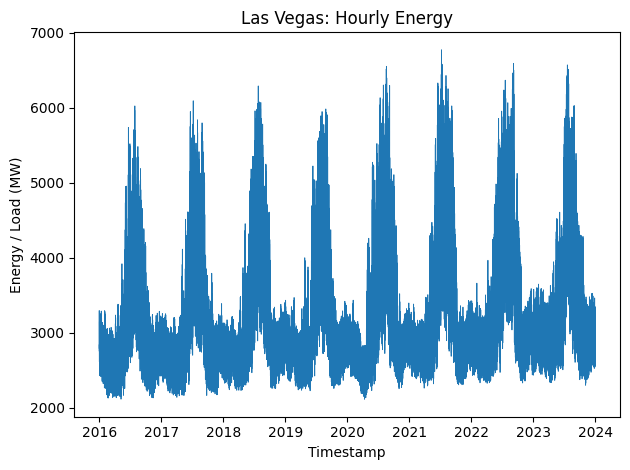

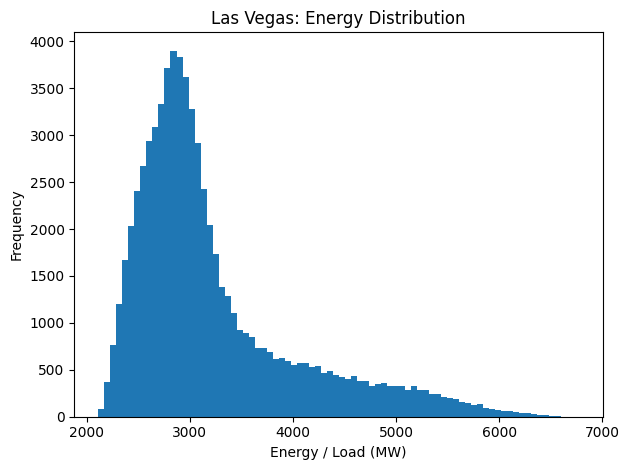

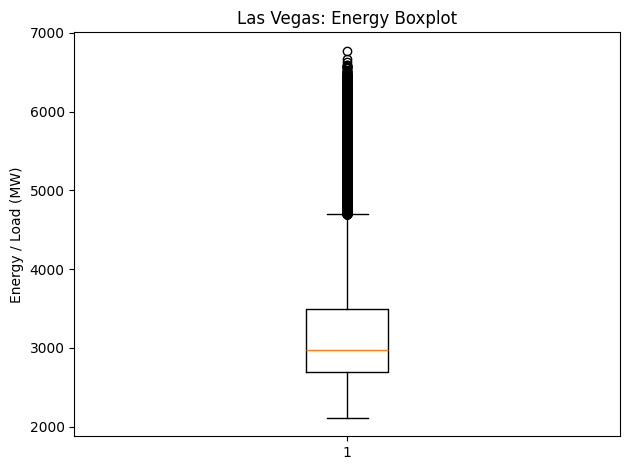

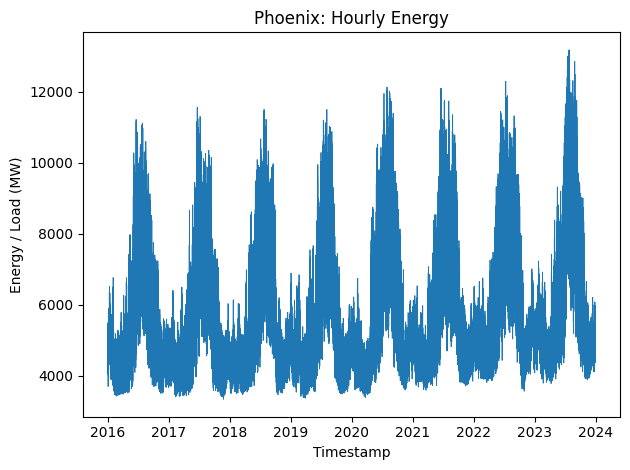

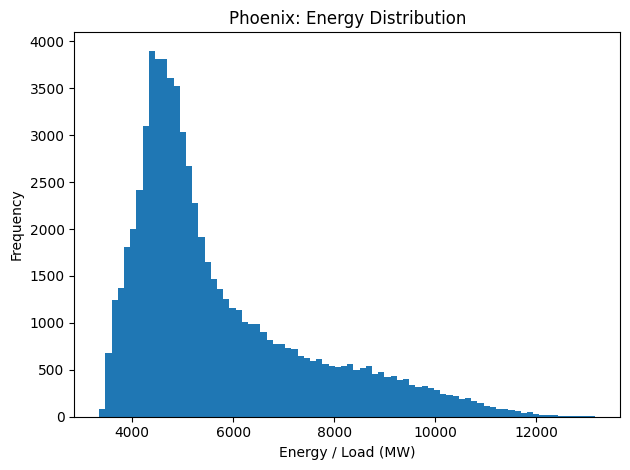

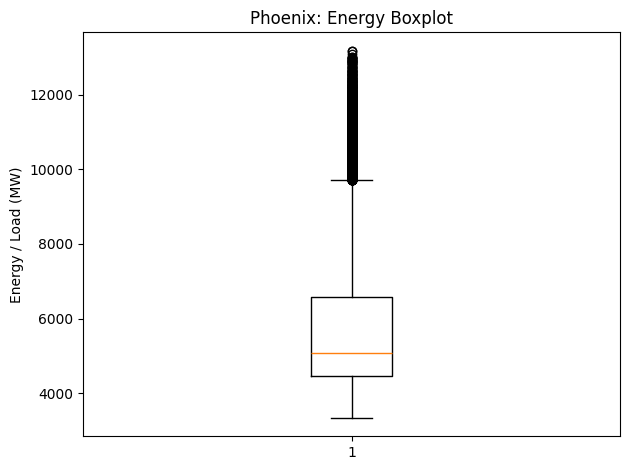

In [14]:
for city, df in merged.items():
    safe = city.lower().replace(" ", "_")

    fig, ax = plt.subplots()
    ax.plot(df["timestamp"], df["hourly_load_mw"], linewidth=0.6)
    ax.set_title(f"{city}: Hourly Energy")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Energy / Load (MW)")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_timeseries.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots()
    ax.hist(df["hourly_load_mw"].dropna(), bins=80)
    ax.set_title(f"{city}: Energy Distribution")
    ax.set_xlabel("Energy / Load (MW)")
    ax.set_ylabel("Frequency")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_distribution.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots()
    ax.boxplot(df["hourly_load_mw"].dropna())
    ax.set_title(f"{city}: Energy Boxplot")
    ax.set_ylabel("Energy / Load (MW)")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_boxplot.png", dpi=160)
    plt.show()


## 8. Identify weather variables

In [15]:
calendar_cols = {
    "hour",
    "day_of_week",
    "month",
    "day_of_year",
    "year",
    "is_weekend",
    "hourly_load_mw",
}

weather_numeric = {}

for city, df in merged.items():
    weather_numeric[city] = [
        c for c in df.select_dtypes(include=np.number).columns
        if c not in calendar_cols
    ]

    print("\n" + city)
    print(weather_numeric[city])



Las Vegas
['extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm']

Phoenix
['extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_s

## 9. Weather distributions and outliers

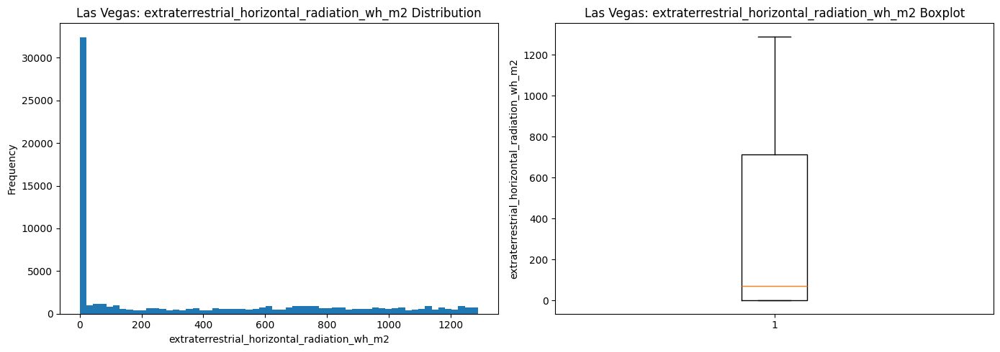

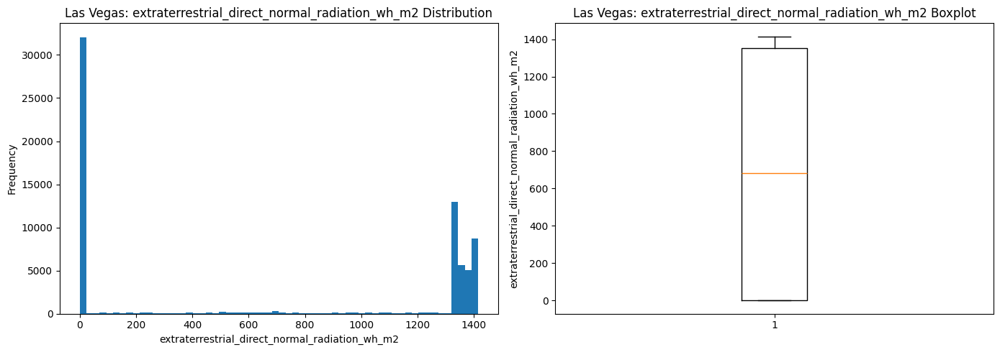

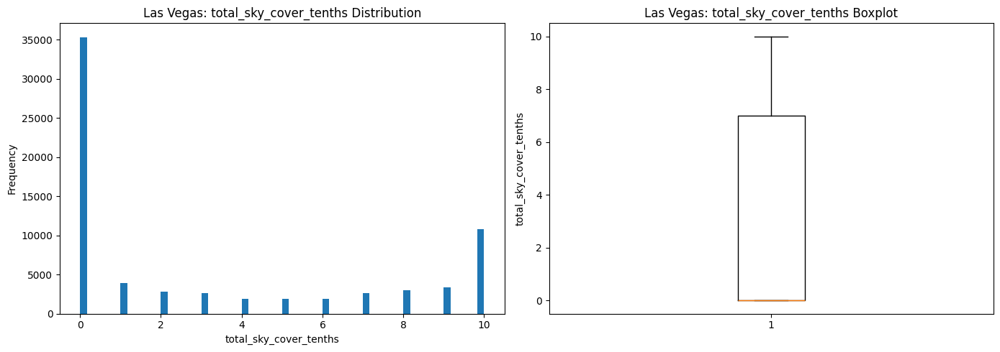

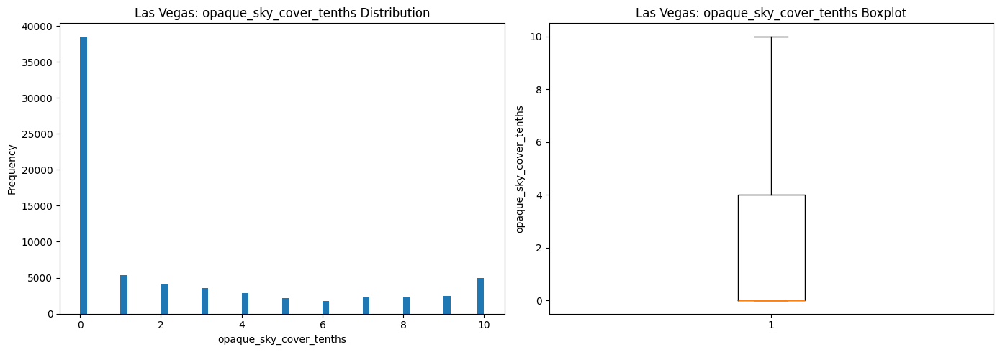

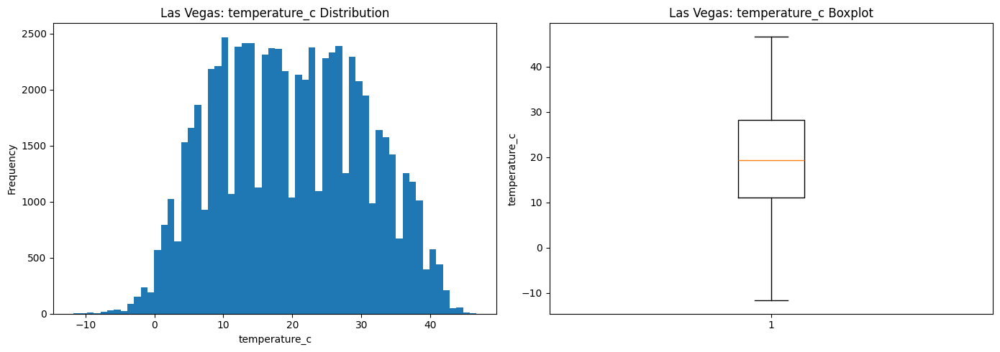

...

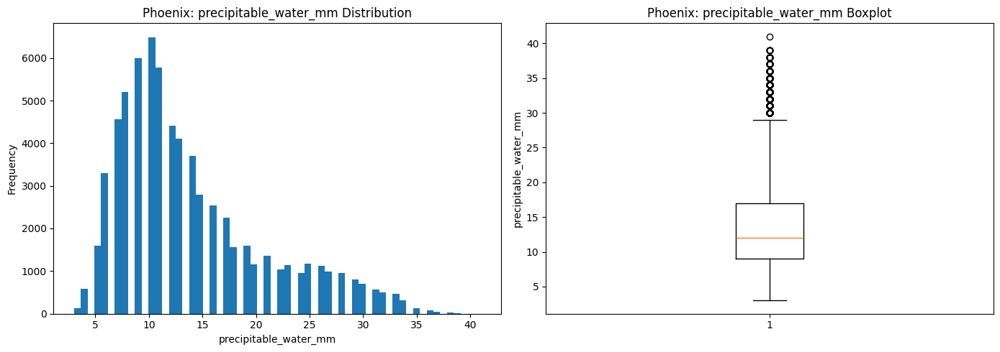

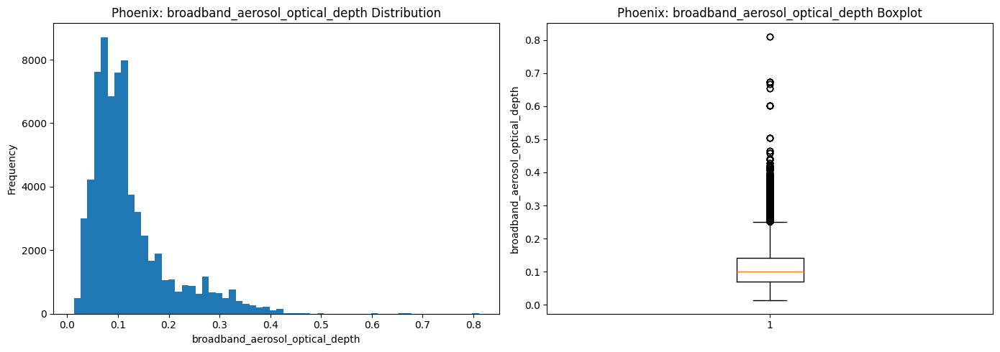

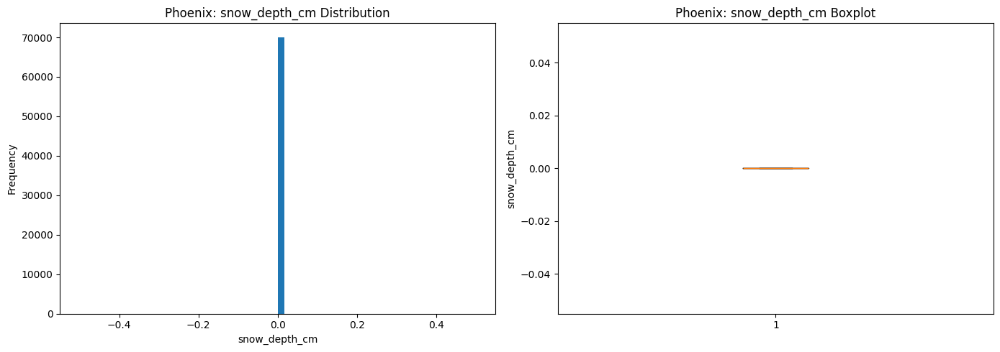

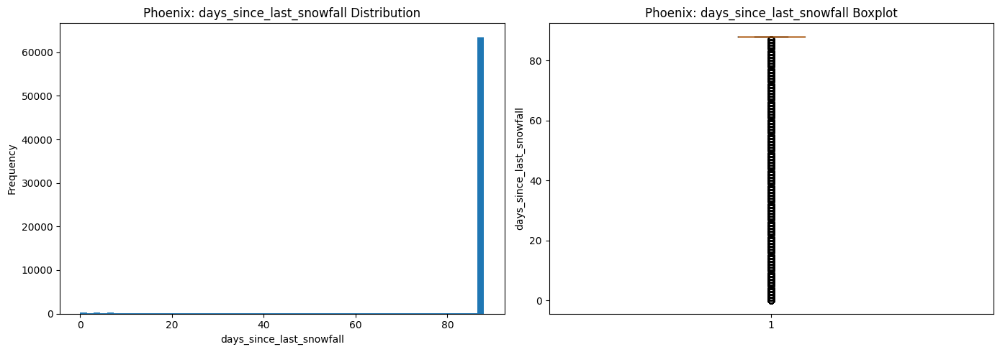

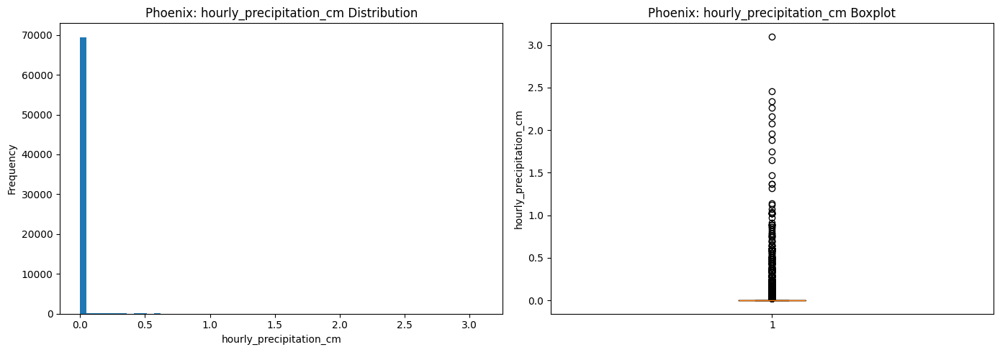

In [16]:
for city, df in merged.items():
    safe = city.lower().replace(" ", "_")

    for col in weather_numeric[city]:
        values = df[col].dropna()

        if len(values) == 0:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].hist(values, bins=60)
        axes[0].set_title(f"{city}: {col} Distribution")
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Frequency")

        axes[1].boxplot(values)
        axes[1].set_title(f"{city}: {col} Boxplot")
        axes[1].set_ylabel(col)

        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{safe}_{col}_distribution.png",
            dpi=140
        )
        plt.show()


## 10. Weather × weather: Pearson correlation matrix

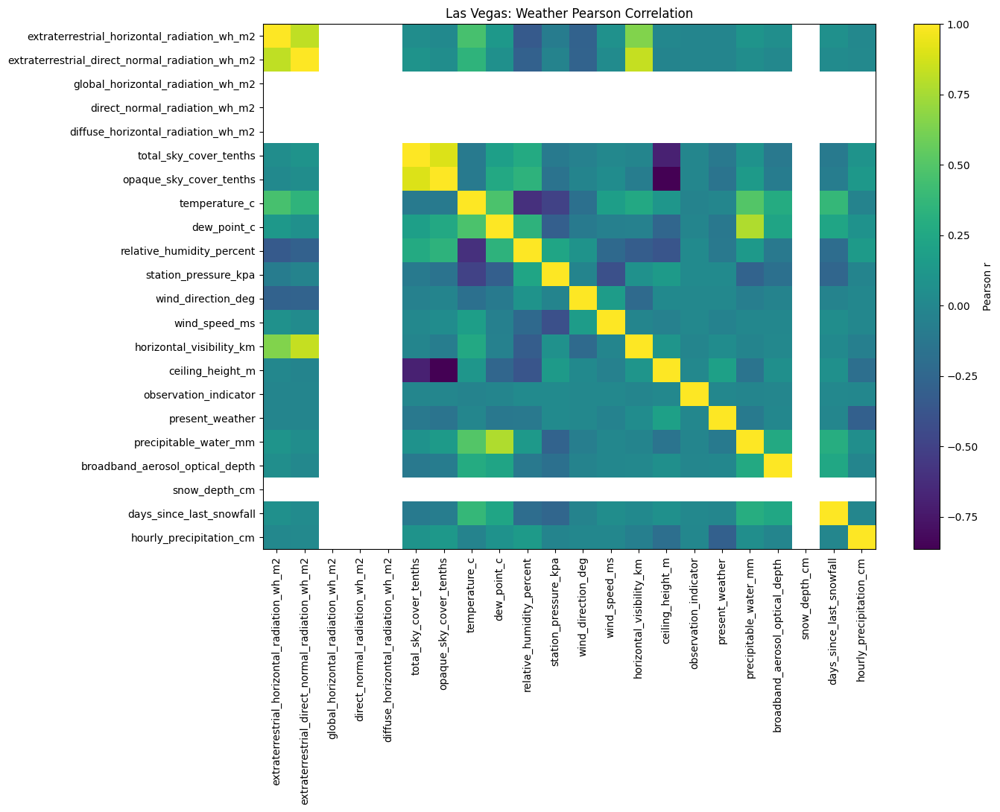

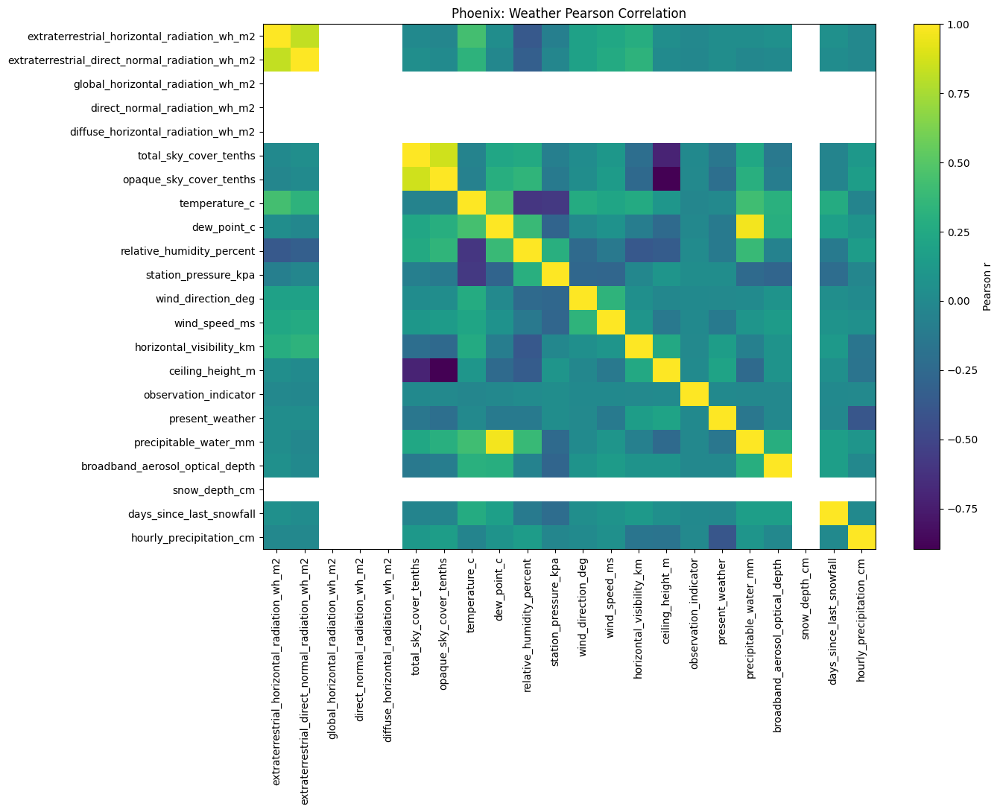

In [17]:
pearson_weather = {}

for city, df in merged.items():
    cols = weather_numeric[city]
    corr = df[cols].corr(method="pearson")
    pearson_weather[city] = corr

    corr.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_weather_pearson.csv"
    )

    fig, ax = plt.subplots(figsize=(14, 11))
    im = ax.imshow(corr.values, aspect="auto")
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=90)
    ax.set_yticklabels(cols)
    ax.set_title(f"{city}: Weather Pearson Correlation")
    fig.colorbar(im, ax=ax, label="Pearson r")
    fig.tight_layout()
    fig.savefig(
        PLOT_DIR / f"{city.lower().replace(' ', '_')}_weather_pearson_heatmap.png",
        dpi=160
    )
    plt.show()


## 11. Weather × weather: Spearman correlation matrix

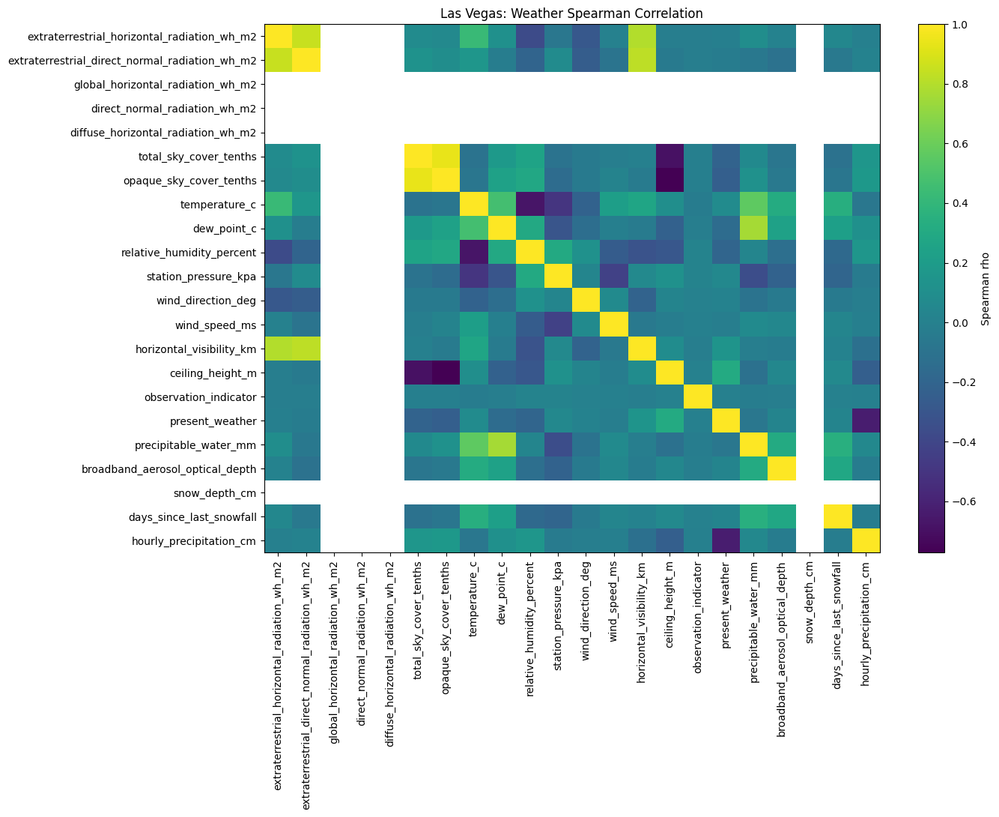

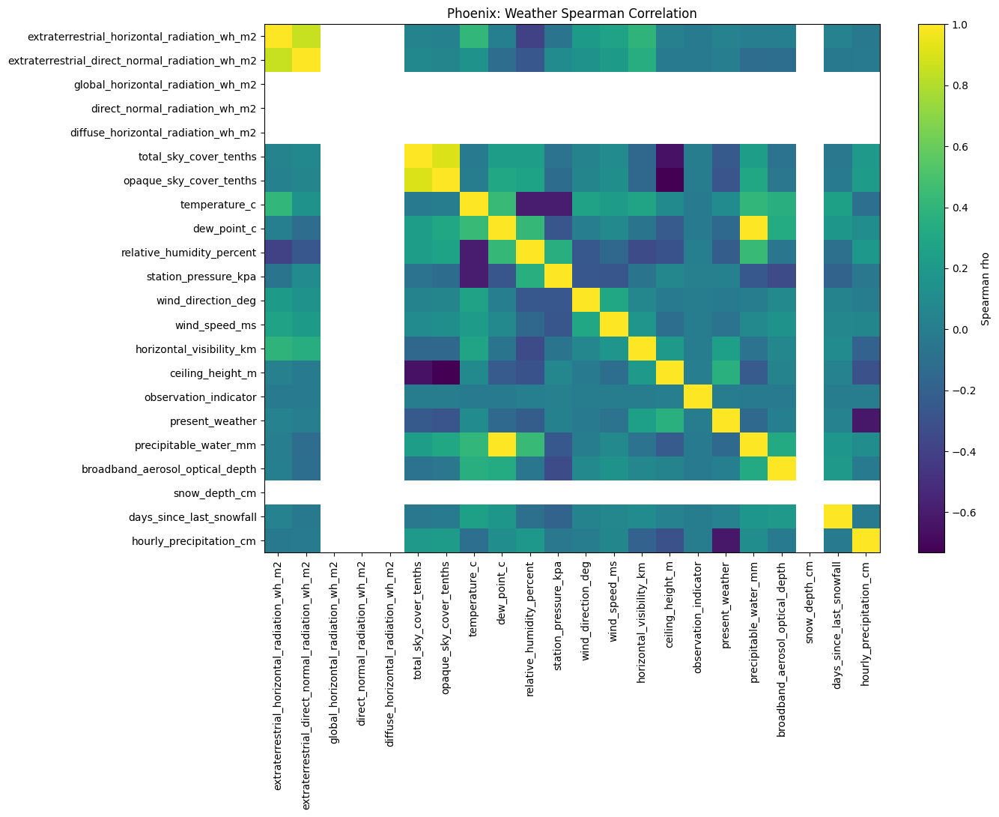

In [18]:
spearman_weather = {}

for city, df in merged.items():
    cols = weather_numeric[city]
    corr = df[cols].corr(method="spearman")
    spearman_weather[city] = corr

    corr.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_weather_spearman.csv"
    )

    fig, ax = plt.subplots(figsize=(14, 11))
    im = ax.imshow(corr.values, aspect="auto")
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=90)
    ax.set_yticklabels(cols)
    ax.set_title(f"{city}: Weather Spearman Correlation")
    fig.colorbar(im, ax=ax, label="Spearman rho")
    fig.tight_layout()
    fig.savefig(
        PLOT_DIR / f"{city.lower().replace(' ', '_')}_weather_spearman_heatmap.png",
        dpi=160
    )
    plt.show()


## 12. Strong weather-weather pairs

This explicitly lists redundant or strongly coupled weather parameters.


In [19]:
def strong_pairs(corr, threshold=0.70):
    rows = []
    cols = list(corr.columns)

    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            value = corr.iloc[i, j]

            if pd.notna(value) and abs(value) >= threshold:
                rows.append({
                    "feature_1": cols[i],
                    "feature_2": cols[j],
                    "correlation": value,
                    "absolute_correlation": abs(value),
                })

    return (
        pd.DataFrame(rows)
        .sort_values("absolute_correlation", ascending=False)
        if rows else
        pd.DataFrame(columns=[
            "feature_1", "feature_2",
            "correlation", "absolute_correlation"
        ])
    )


for city in merged:
    print("\n" + "=" * 80)
    print("HIGH WEATHER-WEATHER CORRELATIONS:", city)
    pairs = strong_pairs(pearson_weather[city], 0.70)
    display(pairs)

    pairs.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_strong_weather_pairs.csv",
        index=False
    )



HIGH WEATHER-WEATHER CORRELATIONS: Las Vegas


,feature_1,feature_2,correlation,absolute_correlation
2,total_sky_cover_tenths,opaque_sky_cover_tenths,0.901220,0.901220
3,opaque_sky_cover_tenths,ceiling_height_m,-0.865850,0.865850
1,extraterrestrial_direct_normal_radiation_wh_m2,horizontal_visibility_km,0.835766,0.835766
0,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,0.821990,0.821990
4,dew_point_c,precipitable_water_mm,0.776371,0.776371



HIGH WEATHER-WEATHER CORRELATIONS: Phoenix


,feature_1,feature_2,correlation,absolute_correlation
4,dew_point_c,precipitable_water_mm,0.965941,0.965941
3,opaque_sky_cover_tenths,ceiling_height_m,-0.897114,0.897114
1,total_sky_cover_tenths,opaque_sky_cover_tenths,0.863267,0.863267
0,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,0.829044,0.829044
2,total_sky_cover_tenths,ceiling_height_m,-0.711144,0.711144


## 13. Scatter plots for strongest weather-weather relationships

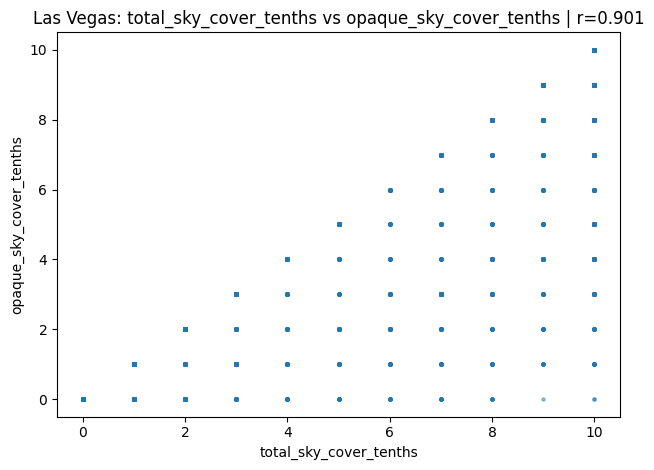

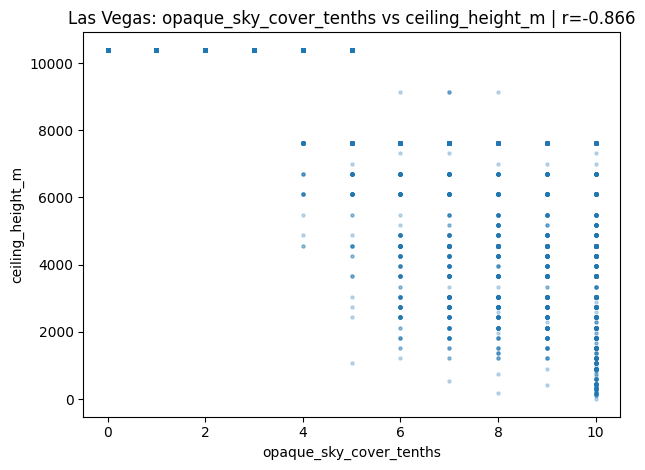

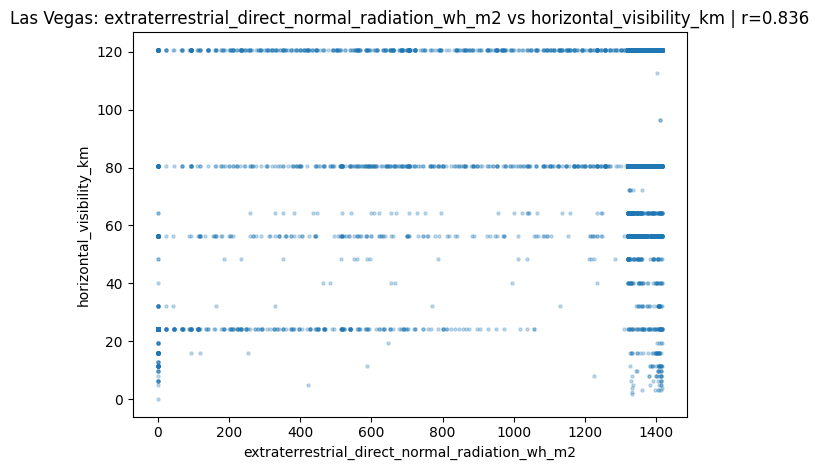

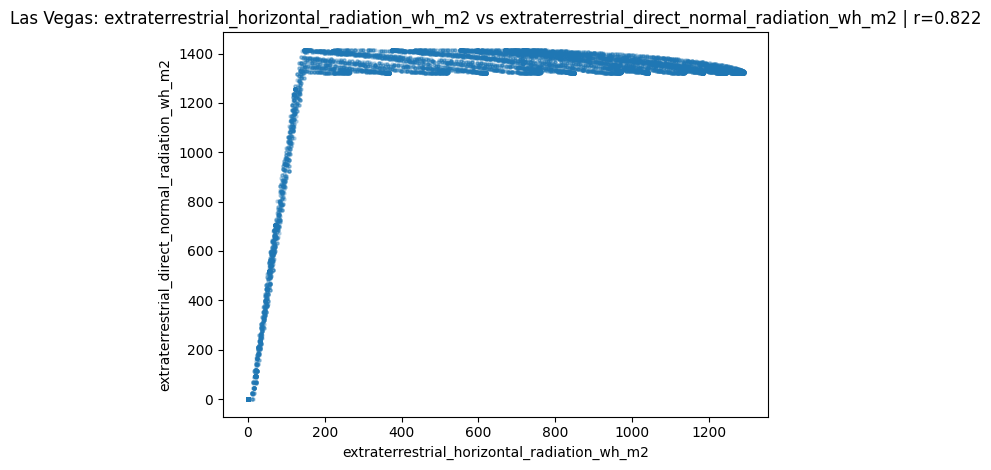

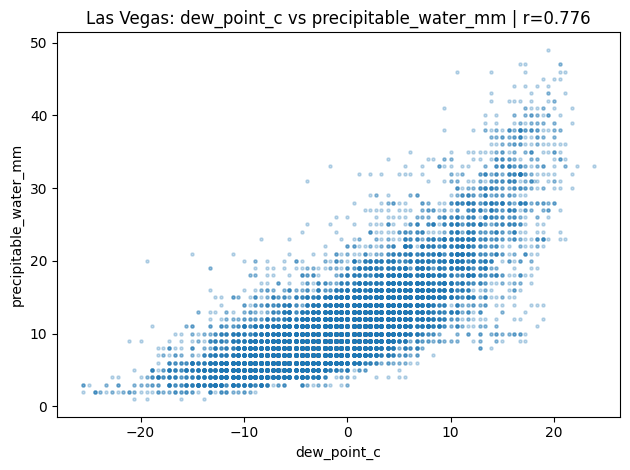

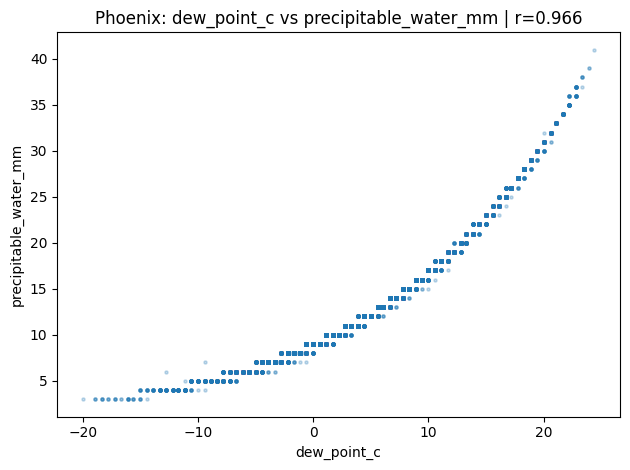

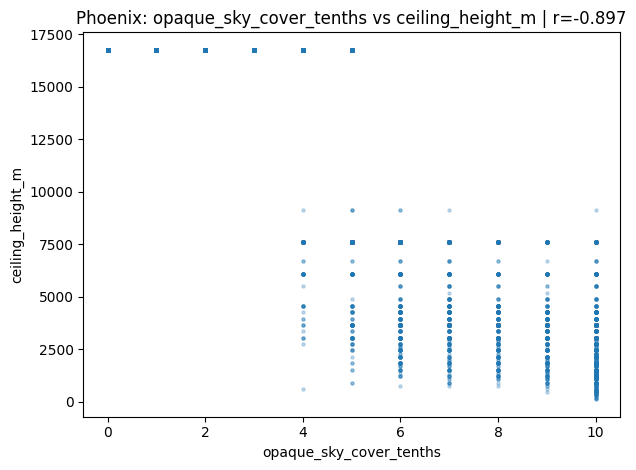

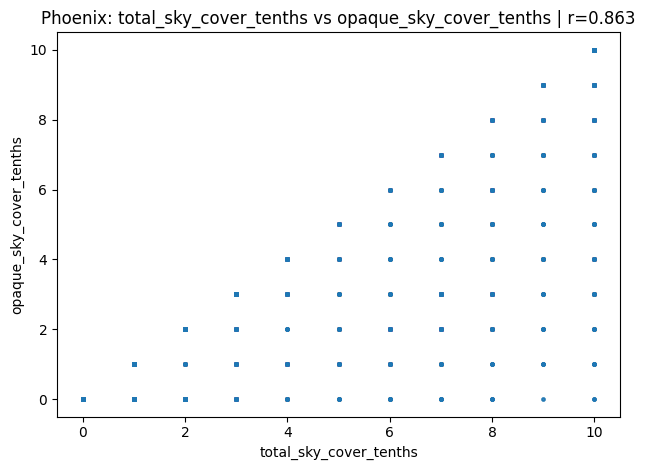

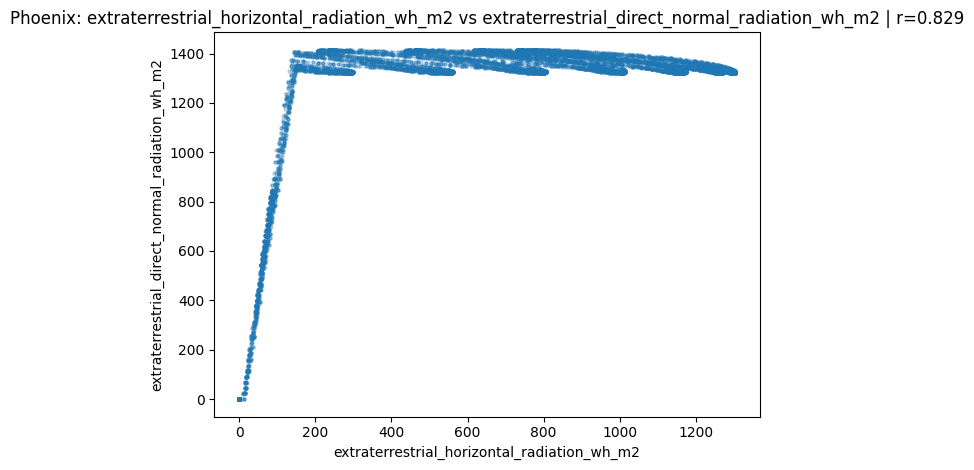

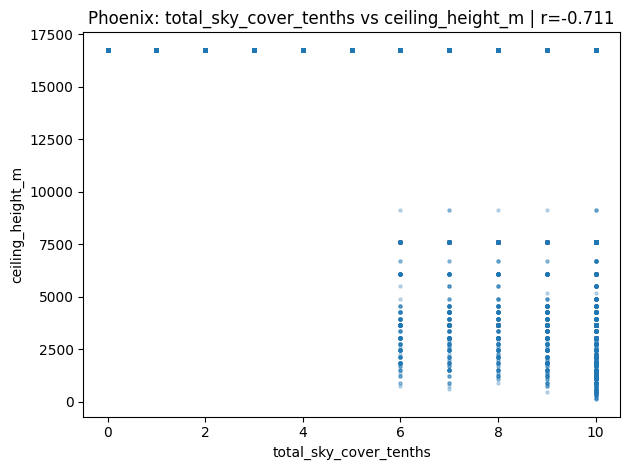

In [20]:
for city in merged:
    pairs = strong_pairs(pearson_weather[city], 0.70).head(15)
    safe = city.lower().replace(" ", "_")

    for _, row in pairs.iterrows():
        xcol = row["feature_1"]
        ycol = row["feature_2"]

        sample = merged[city][[xcol, ycol]].dropna()

        if len(sample) > 15000:
            sample = sample.sample(15000, random_state=42)

        fig, ax = plt.subplots()
        ax.scatter(sample[xcol], sample[ycol], s=5, alpha=0.25)
        ax.set_title(
            f"{city}: {xcol} vs {ycol} | r={row['correlation']:.3f}"
        )
        ax.set_xlabel(xcol)
        ax.set_ylabel(ycol)
        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{safe}_weather_pair_{xcol}_{ycol}.png",
            dpi=130
        )
        plt.show()


## 14. Weather × absolute energy correlations

In [21]:
energy_corr_reports = {}

for city, df in merged.items():
    cols = weather_numeric[city]

    p = (
        df[cols + ["hourly_load_mw"]]
        .corr(method="pearson")["hourly_load_mw"]
        .drop("hourly_load_mw")
    )

    s = (
        df[cols + ["hourly_load_mw"]]
        .corr(method="spearman")["hourly_load_mw"]
        .drop("hourly_load_mw")
    )

    report = pd.DataFrame({
        "feature": cols,
        "pearson_energy": p.reindex(cols).values,
        "spearman_energy": s.reindex(cols).values,
    })

    report["abs_pearson"] = report["pearson_energy"].abs()
    report["abs_spearman"] = report["spearman_energy"].abs()

    report = report.sort_values("abs_pearson", ascending=False)
    energy_corr_reports[city] = report

    display(report)

    report.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_weather_energy_correlations.csv",
        index=False
    )


,feature,pearson_energy,spearman_energy,abs_pearson,abs_spearman
17,precipitable_water_mm,0.405468,0.366755,0.405468,0.366755
0,extraterrestrial_horizontal_radiation_wh_m2,-0.385907,-0.443030,0.385907,0.443030
1,extraterrestrial_direct_normal_radiation_wh_m2,-0.382891,-0.537486,0.382891,0.537486
7,temperature_c,0.367080,0.337111,0.367080,0.337111
8,dew_point_c,0.340421,0.300419,0.340421,0.300419
13,horizontal_visibility_km,-0.333850,-0.376871,0.333850,0.376871
10,station_pressure_kpa,-0.259415,-0.262415,0.259415,0.262415
20,days_since_last_snowfall,0.247627,0.248923,0.247627,0.248923
18,broadband_aerosol_optical_depth,0.164891,0.188451,0.164891,0.188451
5,total_sky_cover_tenths,-0.158818,-0.176179,0.158818,0.176179


,feature,pearson_energy,spearman_energy,abs_pearson,abs_spearman
17,precipitable_water_mm,0.486899,0.421395,0.486899,0.421395
8,dew_point_c,0.466647,0.427591,0.466647,0.427591
7,temperature_c,0.448761,0.460750,0.448761,0.460750
10,station_pressure_kpa,-0.384658,-0.414952,0.384658,0.414952
1,extraterrestrial_direct_normal_radiation_wh_m2,-0.349476,-0.435351,0.349476,0.435351
0,extraterrestrial_horizontal_radiation_wh_m2,-0.340589,-0.341691,0.340589,0.341691
18,broadband_aerosol_optical_depth,0.215728,0.281532,0.215728,0.281532
20,days_since_last_snowfall,0.182214,0.240681,0.182214,0.240681
16,present_weather,-0.081570,0.008605,0.081570,0.008605
9,relative_humidity_percent,-0.079218,-0.070958,0.079218,0.070958


## 15. Weather × energy scatter plots

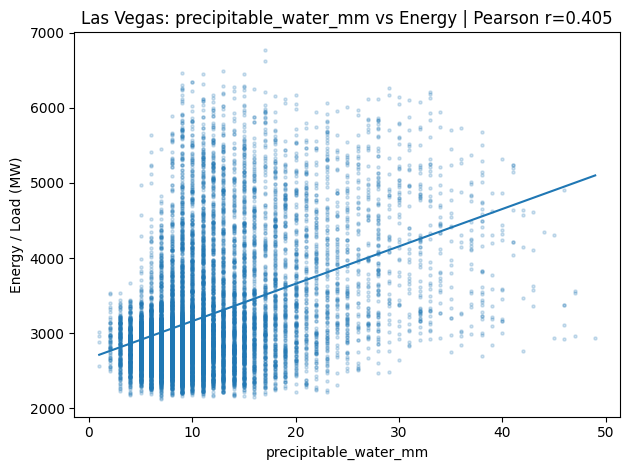

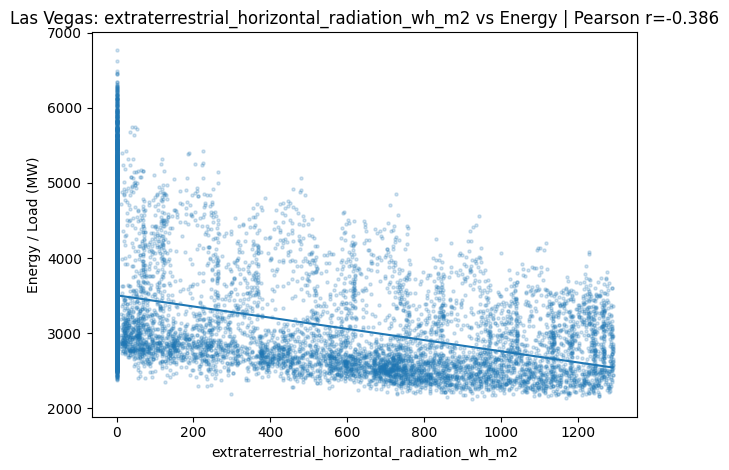

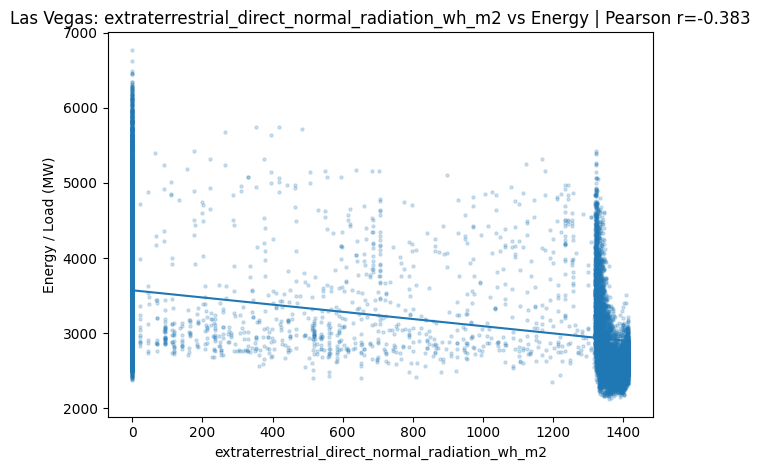

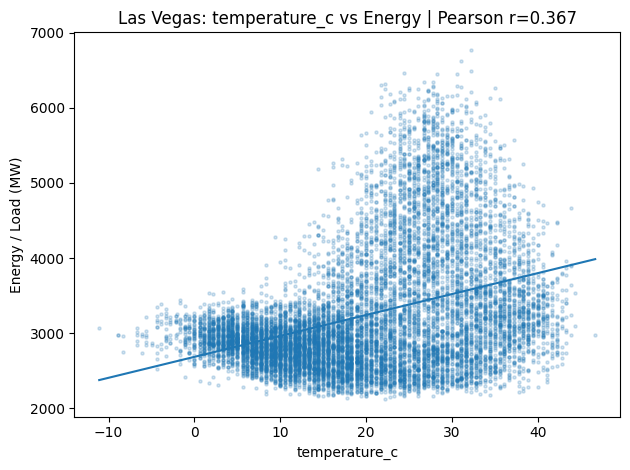

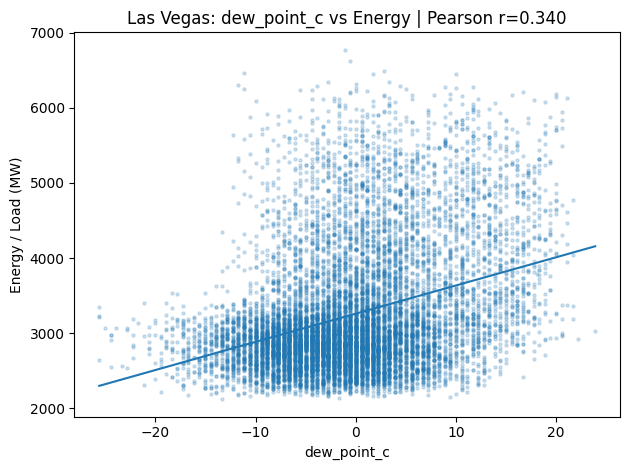

...

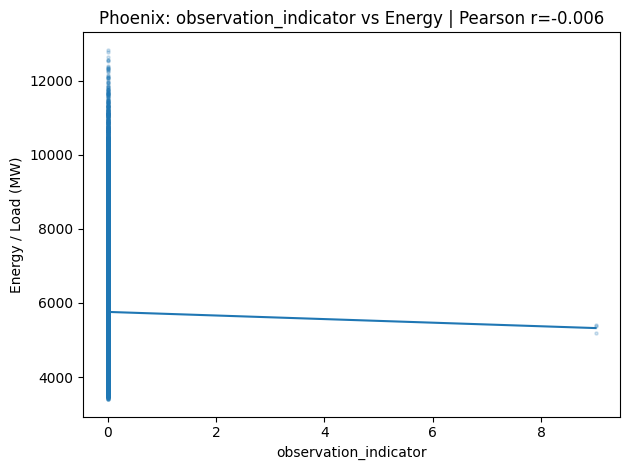

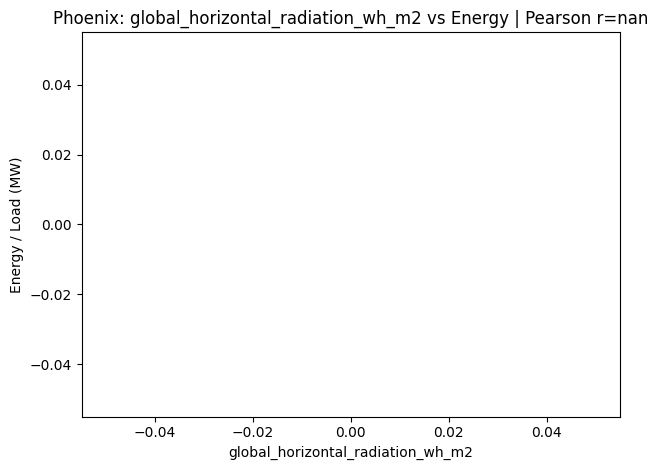

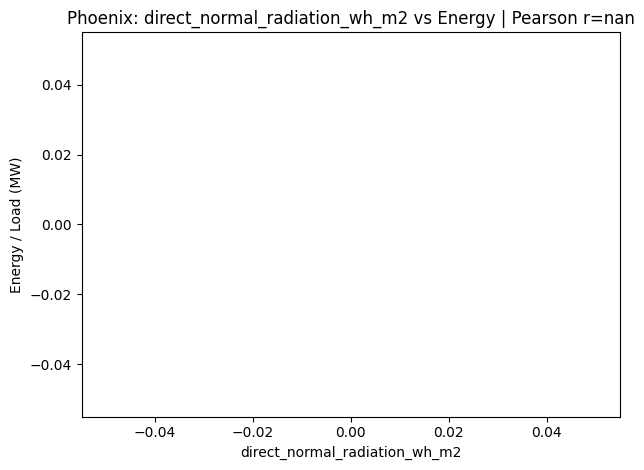

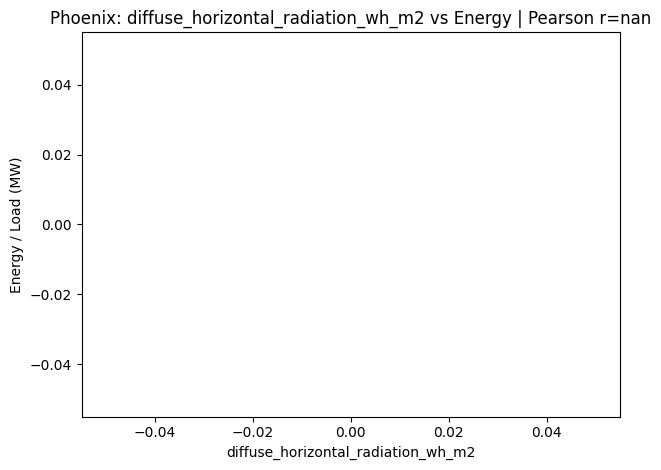

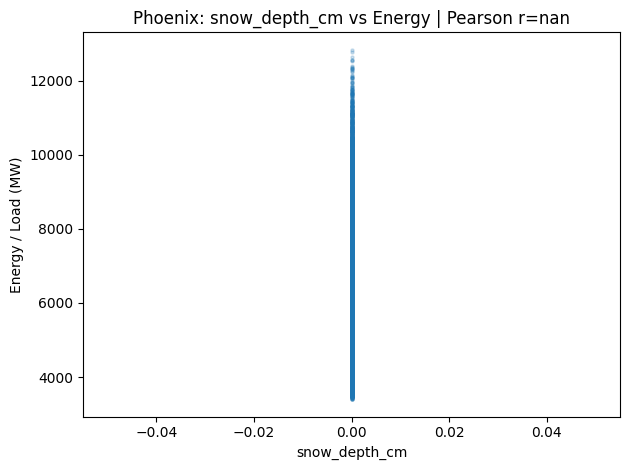

In [22]:
for city, df in merged.items():
    safe = city.lower().replace(" ", "_")

    for col in energy_corr_reports[city]["feature"]:
        sample = df[[col, "hourly_load_mw"]].dropna()

        if len(sample) > 12000:
            sample = sample.sample(12000, random_state=42)

        fig, ax = plt.subplots()
        ax.scatter(sample[col], sample["hourly_load_mw"], s=5, alpha=0.20)

        if sample[col].nunique() > 1:
            x = sample[col].to_numpy()
            y = sample["hourly_load_mw"].to_numpy()
            slope, intercept = np.polyfit(x, y, 1)
            grid = np.linspace(np.nanmin(x), np.nanmax(x), 100)
            ax.plot(grid, slope * grid + intercept)

        r = energy_corr_reports[city].loc[
            energy_corr_reports[city]["feature"] == col,
            "pearson_energy"
        ].iloc[0]

        ax.set_title(f"{city}: {col} vs Energy | Pearson r={r:.3f}")
        ax.set_xlabel(col)
        ax.set_ylabel("Energy / Load (MW)")
        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{safe}_energy_vs_{col}.png",
            dpi=130
        )
        plt.show()


## 16. Energy patterns by hour, month, day of week and year

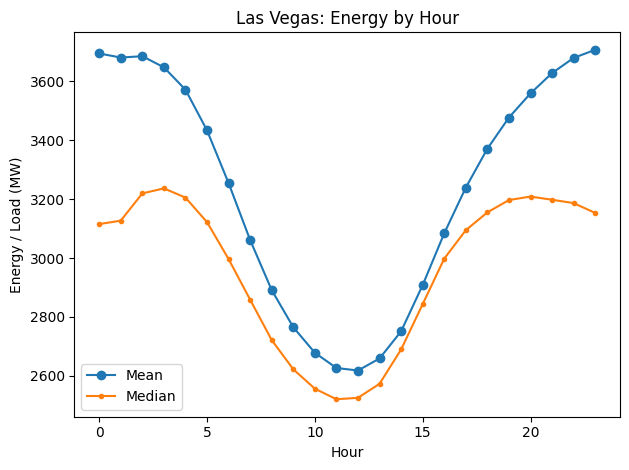

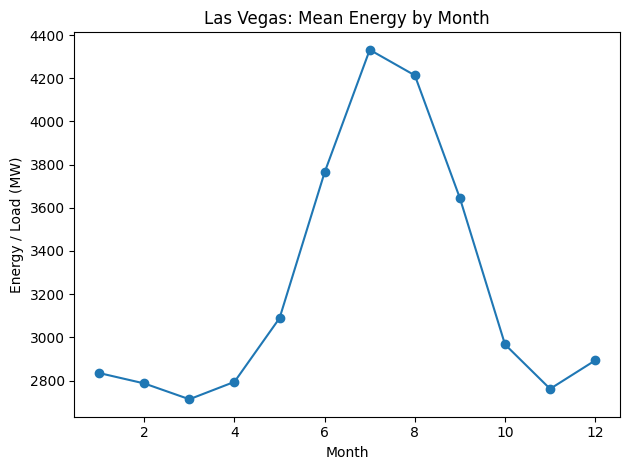

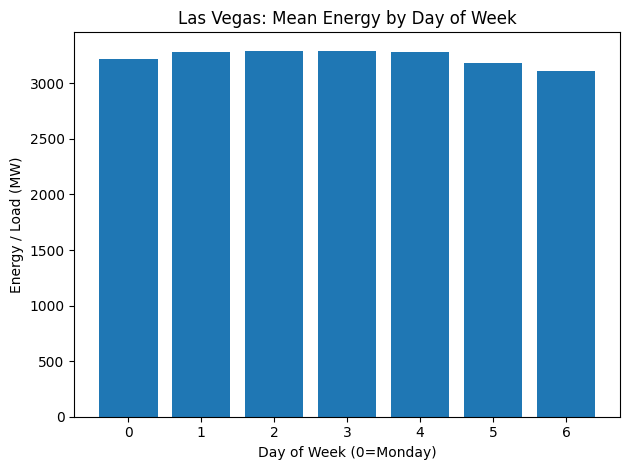

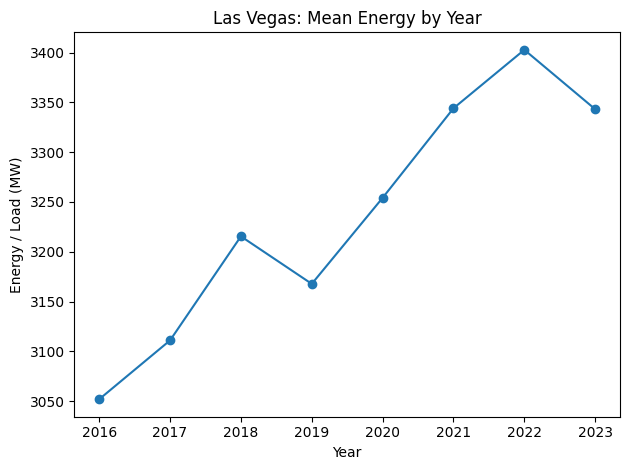

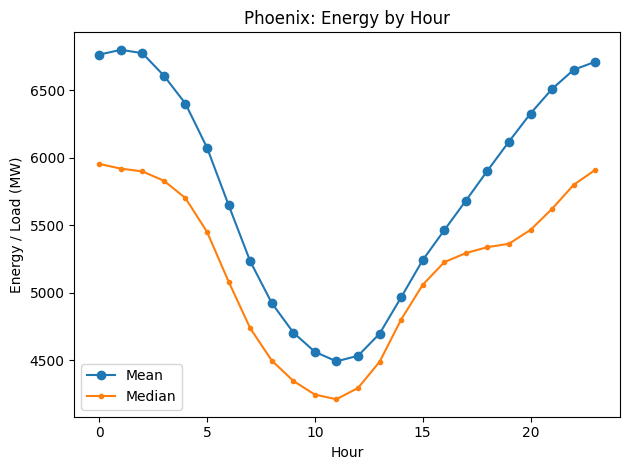

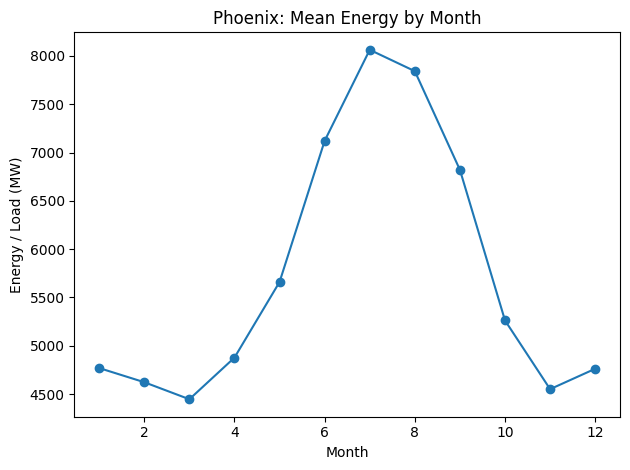

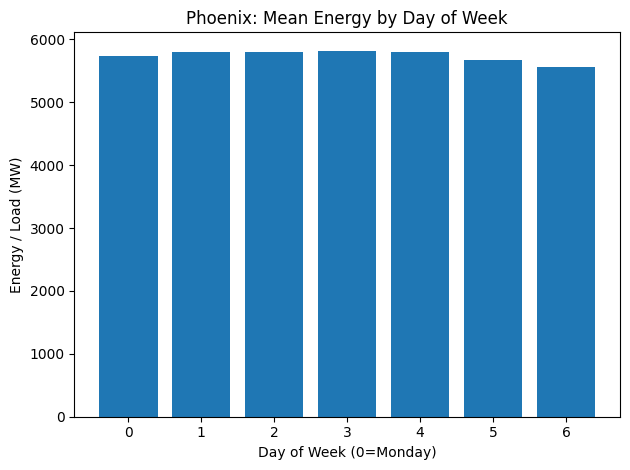

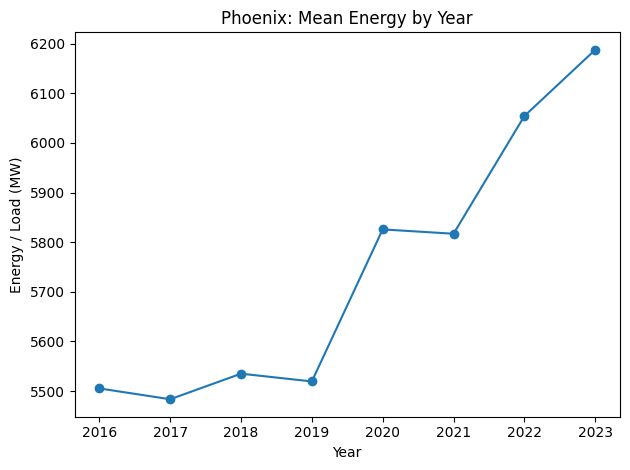

In [23]:
for city, df in merged.items():
    safe = city.lower().replace(" ", "_")

    hourly = df.groupby("hour")["hourly_load_mw"].agg(["mean", "median"])

    fig, ax = plt.subplots()
    ax.plot(hourly.index, hourly["mean"], marker="o", label="Mean")
    ax.plot(hourly.index, hourly["median"], marker=".", label="Median")
    ax.set_title(f"{city}: Energy by Hour")
    ax.set_xlabel("Hour")
    ax.set_ylabel("Energy / Load (MW)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_by_hour.png", dpi=150)
    plt.show()

    monthly = df.groupby("month")["hourly_load_mw"].mean()

    fig, ax = plt.subplots()
    ax.plot(monthly.index, monthly.values, marker="o")
    ax.set_title(f"{city}: Mean Energy by Month")
    ax.set_xlabel("Month")
    ax.set_ylabel("Energy / Load (MW)")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_by_month.png", dpi=150)
    plt.show()

    dow = df.groupby("day_of_week")["hourly_load_mw"].mean()

    fig, ax = plt.subplots()
    ax.bar(dow.index, dow.values)
    ax.set_title(f"{city}: Mean Energy by Day of Week")
    ax.set_xlabel("Day of Week (0=Monday)")
    ax.set_ylabel("Energy / Load (MW)")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_by_dow.png", dpi=150)
    plt.show()

    yearly = df.groupby("year")["hourly_load_mw"].mean()

    fig, ax = plt.subplots()
    ax.plot(yearly.index, yearly.values, marker="o")
    ax.set_title(f"{city}: Mean Energy by Year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Energy / Load (MW)")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{safe}_energy_by_year.png", dpi=150)
    plt.show()


## 17. Conditional weather × energy by hour

A raw correlation can be dominated by the fact that both weather and electricity demand change with time of day. This section calculates the weather-energy correlation separately for each hour.


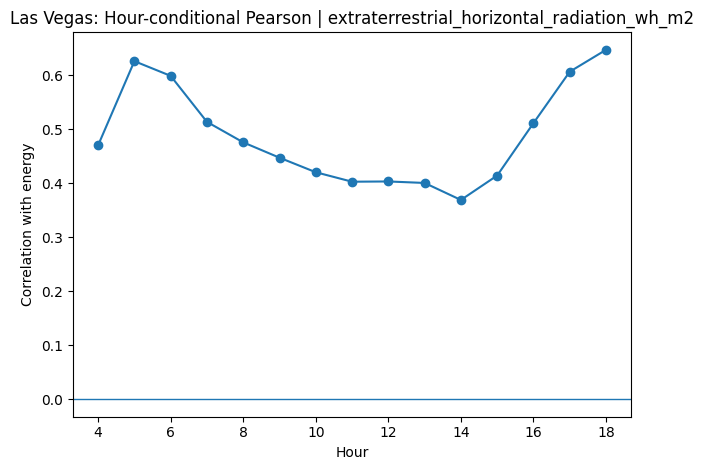

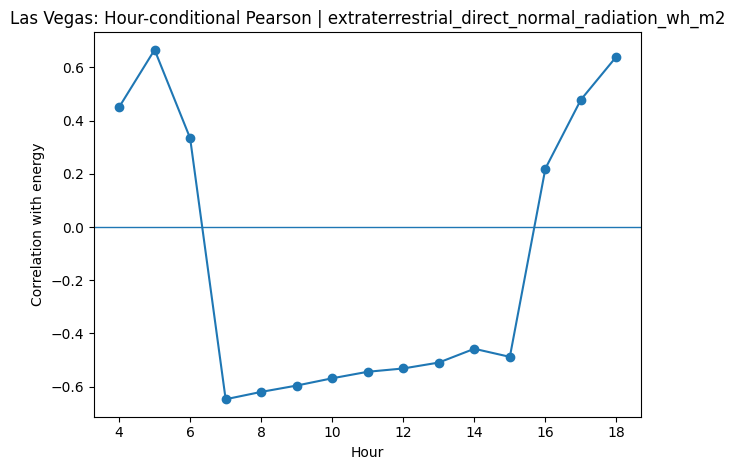

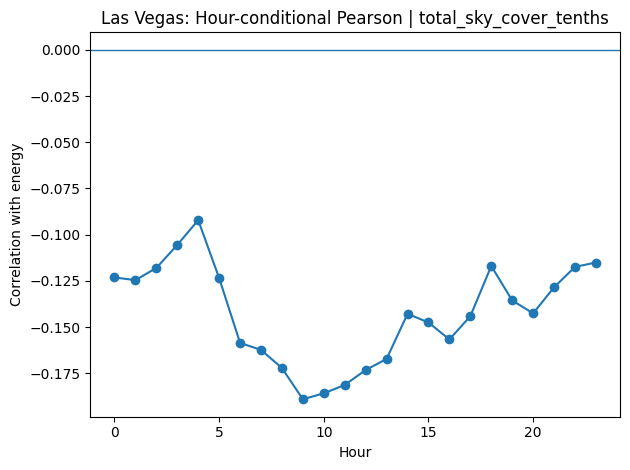

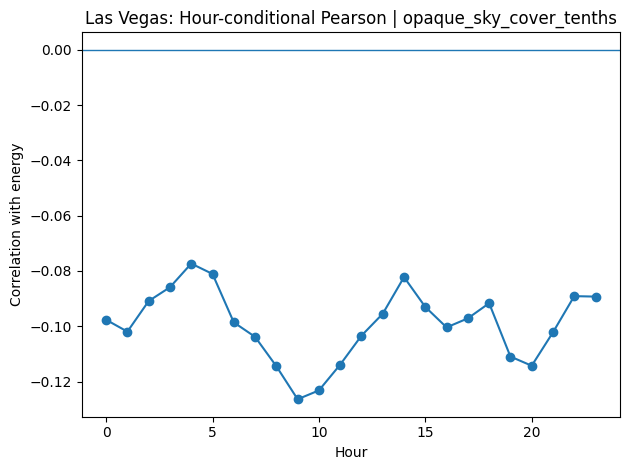

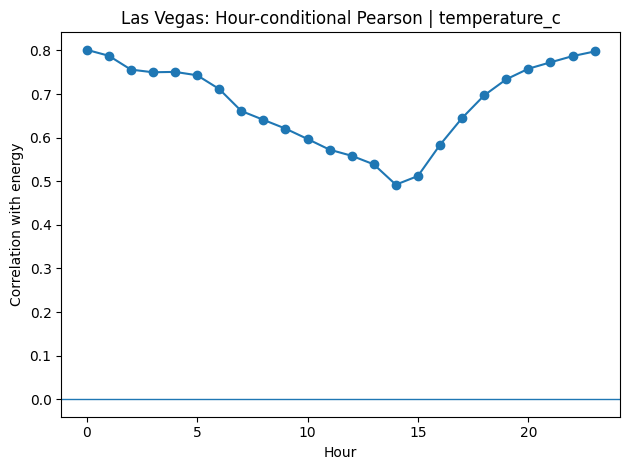

...

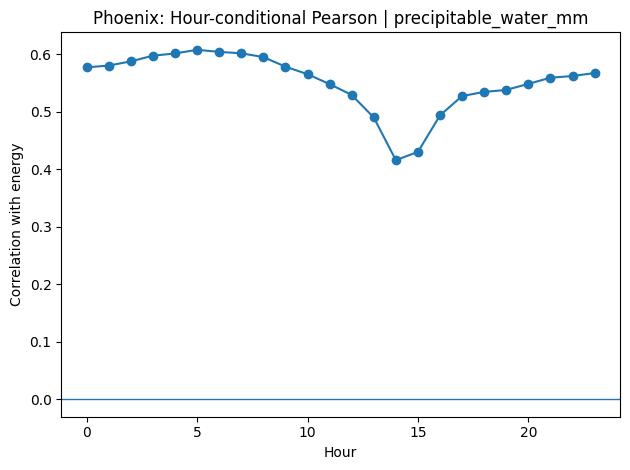

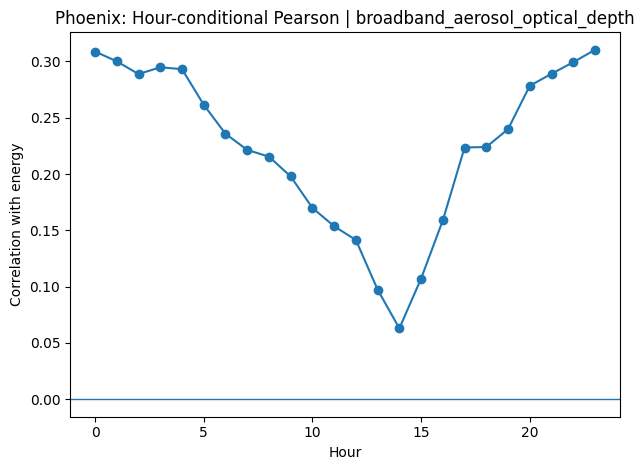

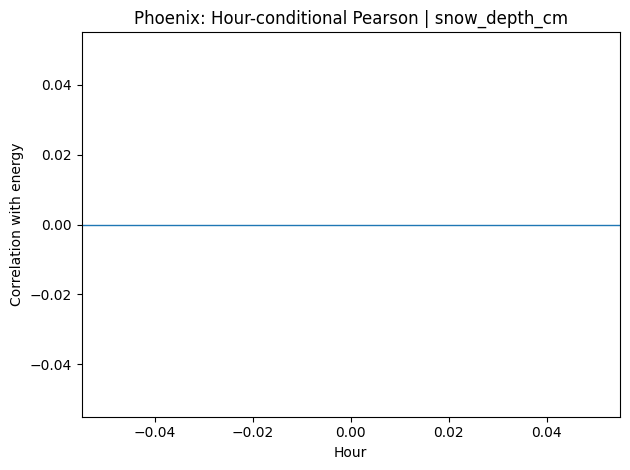

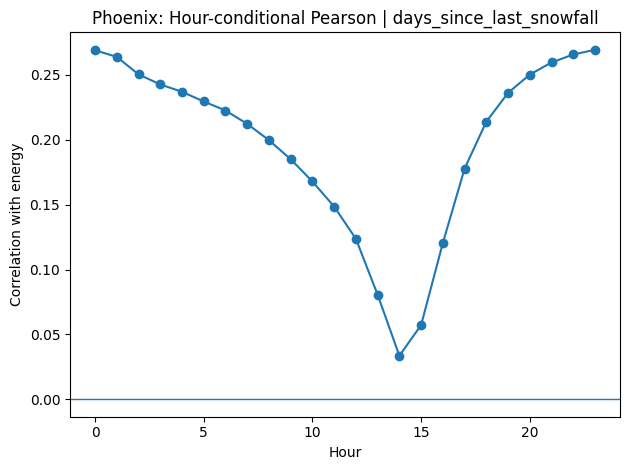

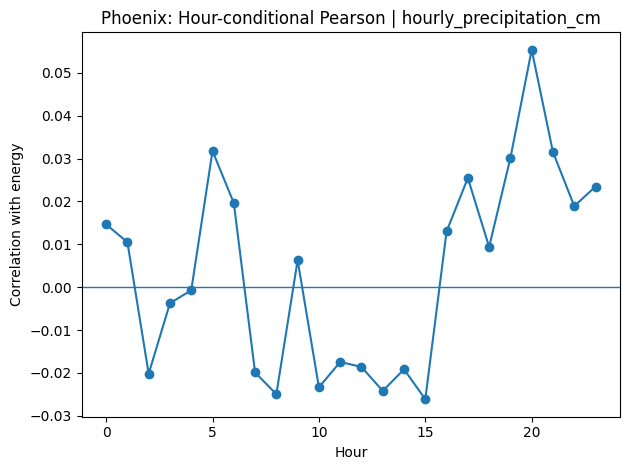

In [24]:
conditional_hour_reports = {}

for city, df in merged.items():
    rows = []

    for feature in weather_numeric[city]:
        for hour in range(24):
            sub = df.loc[
                df["hour"] == hour,
                [feature, "hourly_load_mw"]
            ].dropna()

            if len(sub) < 30:
                continue

            rows.append({
                "feature": feature,
                "hour": hour,
                "n": len(sub),
                "pearson": sub[feature].corr(sub["hourly_load_mw"]),
                "spearman": sub[feature].corr(
                    sub["hourly_load_mw"],
                    method="spearman"
                ),
            })

    report = pd.DataFrame(rows)
    conditional_hour_reports[city] = report

    report.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_hour_conditional_correlations.csv",
        index=False
    )

    for feature in report["feature"].unique():
        sub = report[report["feature"] == feature]

        fig, ax = plt.subplots()
        ax.plot(sub["hour"], sub["pearson"], marker="o")
        ax.axhline(0, linewidth=1)
        ax.set_title(f"{city}: Hour-conditional Pearson | {feature}")
        ax.set_xlabel("Hour")
        ax.set_ylabel("Correlation with energy")
        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{city.lower().replace(' ', '_')}_hour_conditional_{feature}.png",
            dpi=130
        )
        plt.show()


## 18. Conditional weather × energy by season

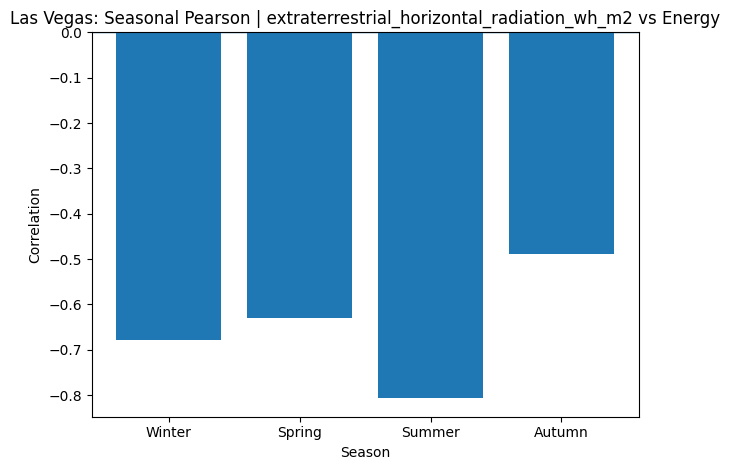

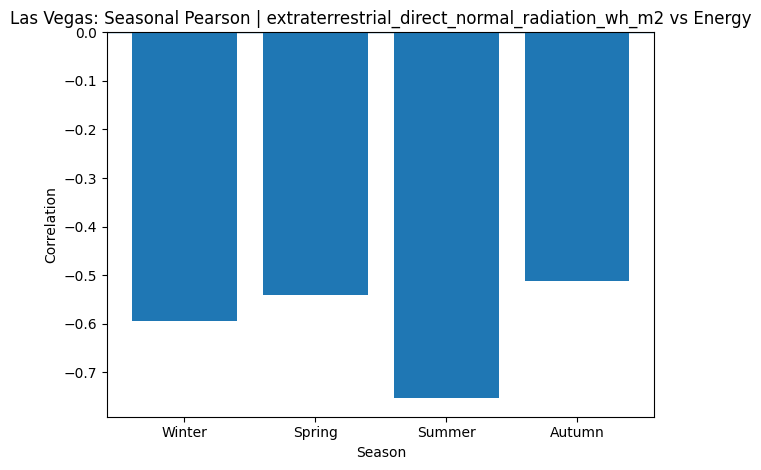

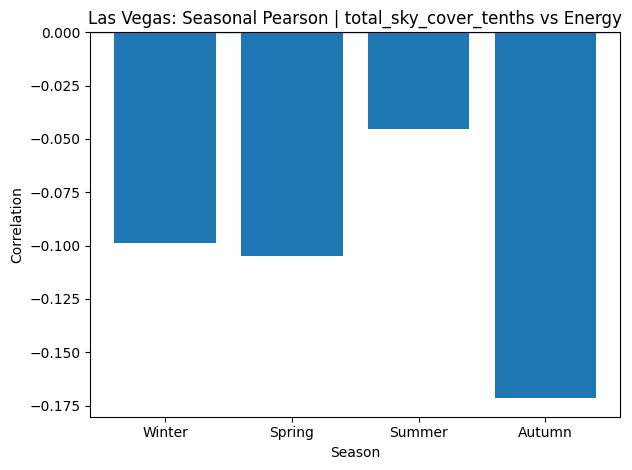

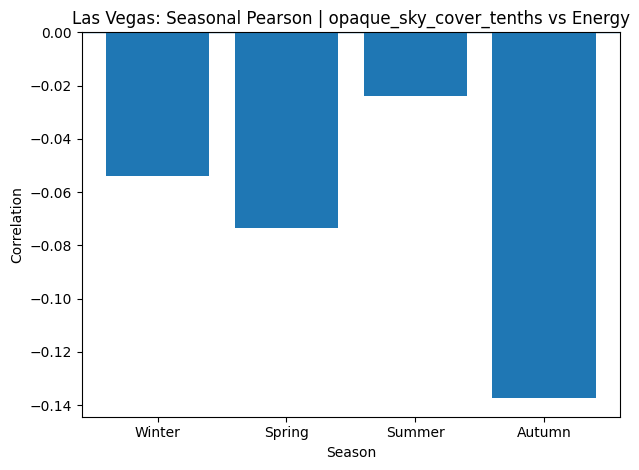

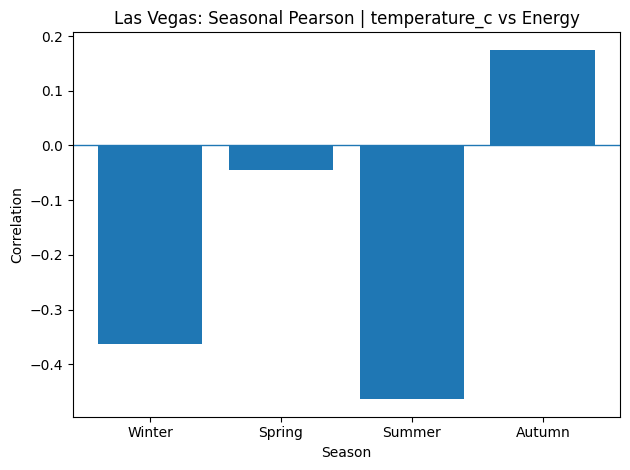

...

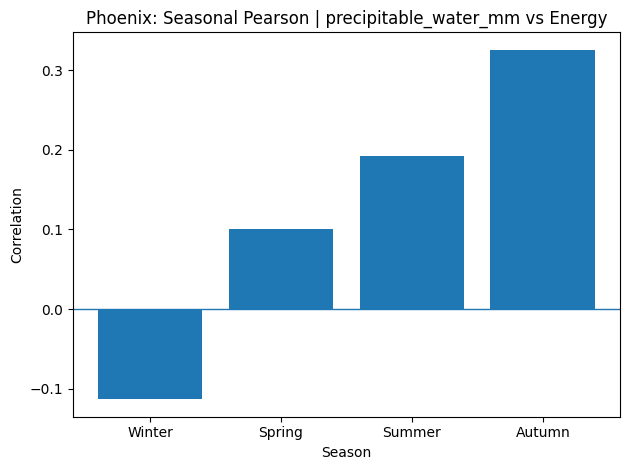

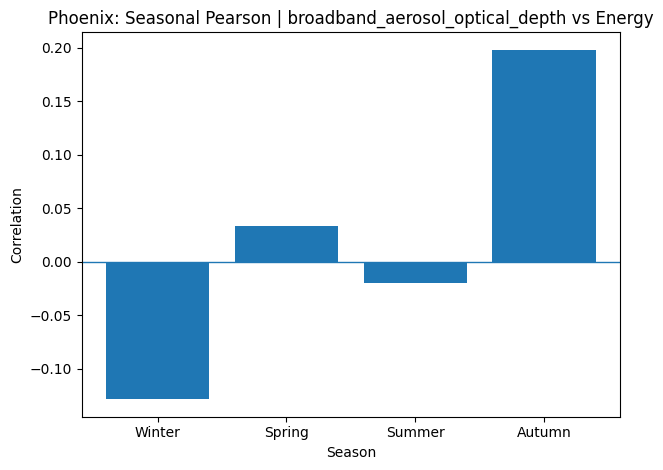

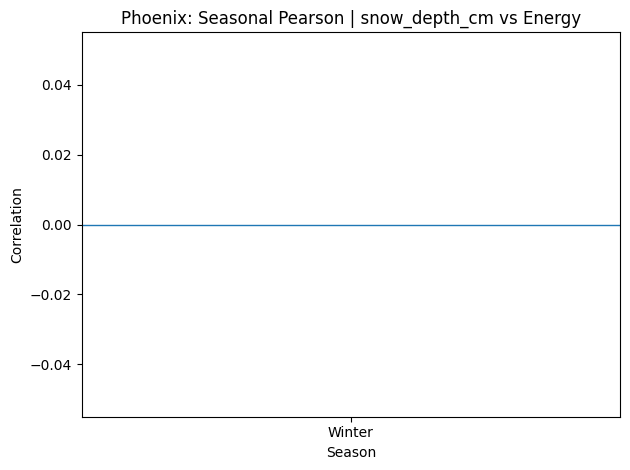

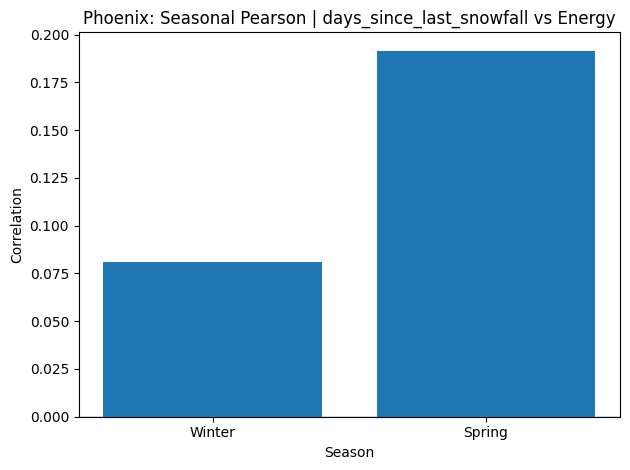

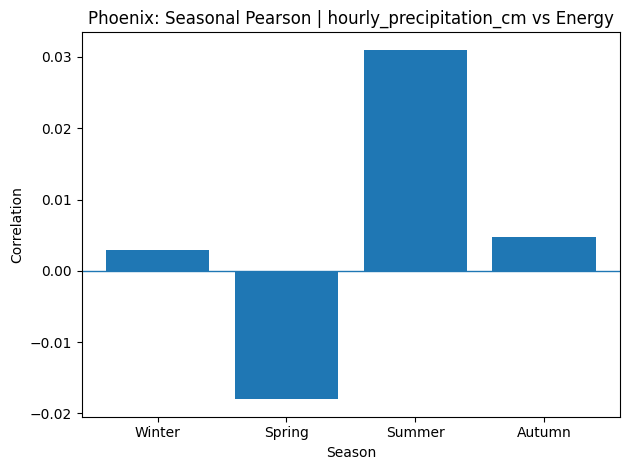

In [25]:
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}

season_reports = {}

for city, df in merged.items():
    temp = df.copy()
    temp["season"] = temp["month"].map(season_map)

    rows = []

    for feature in weather_numeric[city]:
        for season in ["Winter", "Spring", "Summer", "Autumn"]:
            sub = temp.loc[
                temp["season"] == season,
                [feature, "hourly_load_mw"]
            ].dropna()

            if len(sub) < 30:
                continue

            rows.append({
                "feature": feature,
                "season": season,
                "n": len(sub),
                "pearson": sub[feature].corr(sub["hourly_load_mw"]),
                "spearman": sub[feature].corr(
                    sub["hourly_load_mw"],
                    method="spearman"
                ),
            })

    report = pd.DataFrame(rows)
    season_reports[city] = report

    report.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_season_weather_energy.csv",
        index=False
    )

    for feature in report["feature"].unique():
        sub = report[report["feature"] == feature]

        fig, ax = plt.subplots()
        ax.bar(sub["season"], sub["pearson"])
        ax.axhline(0, linewidth=1)
        ax.set_title(f"{city}: Seasonal Pearson | {feature} vs Energy")
        ax.set_xlabel("Season")
        ax.set_ylabel("Correlation")
        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{city.lower().replace(' ', '_')}_seasonal_{feature}.png",
            dpi=130
        )
        plt.show()


## 19. Temperature response curves

Temperature is often nonlinear with electricity demand. This section avoids assuming a straight line.


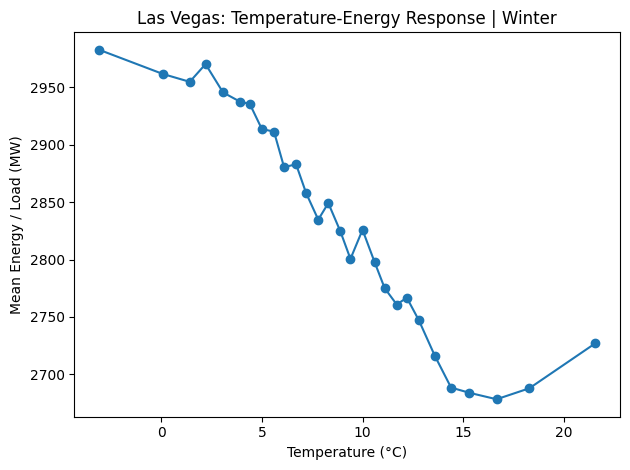

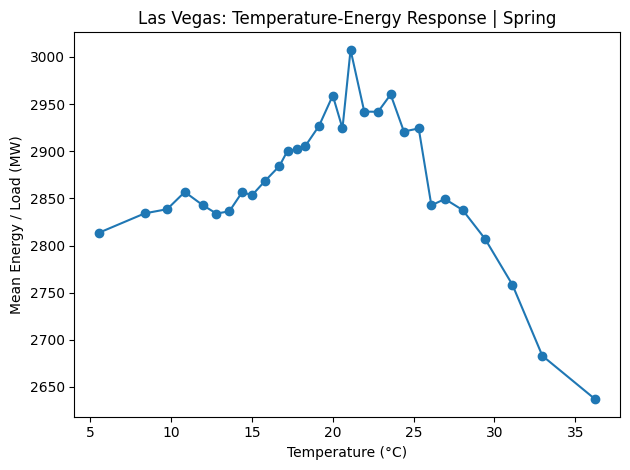

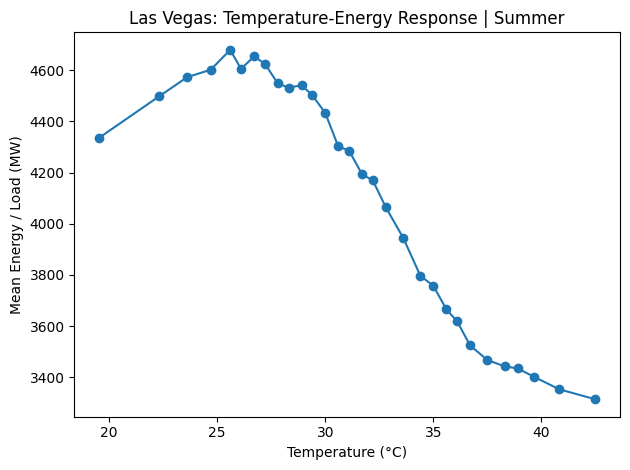

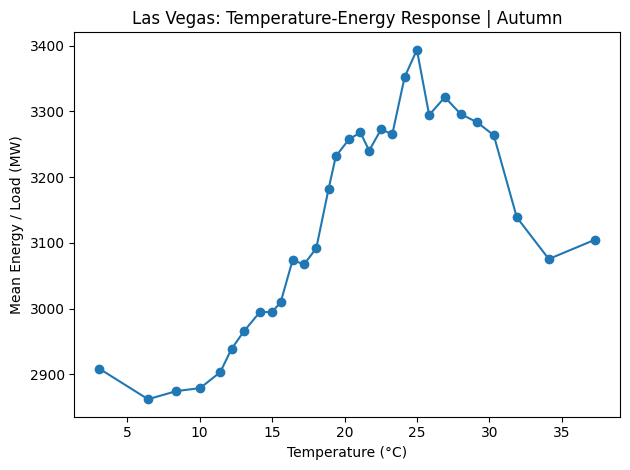

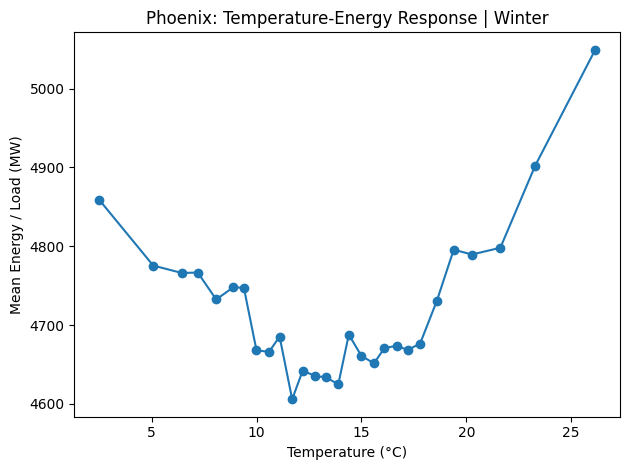

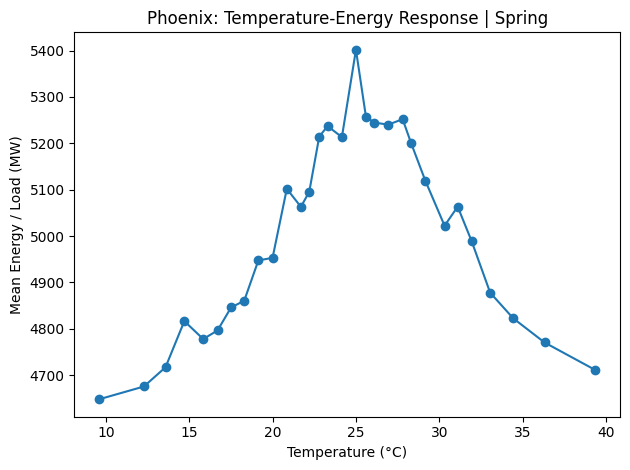

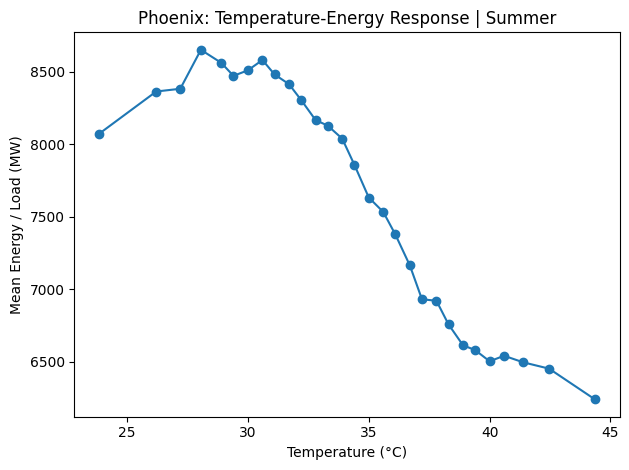

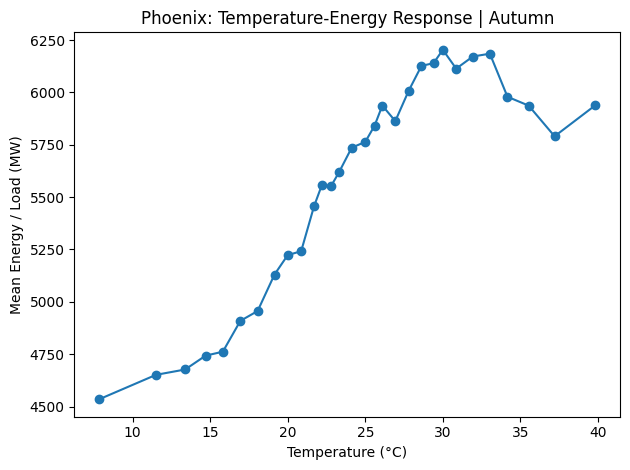

In [26]:
for city, df in merged.items():
    if "temperature_c" not in df.columns:
        continue

    temp = df[["temperature_c", "hourly_load_mw", "month"]].dropna().copy()
    temp["season"] = temp["month"].map(season_map)

    for season in ["Winter", "Spring", "Summer", "Autumn"]:
        sub = temp[temp["season"] == season].copy()

        if len(sub) < 100:
            continue

        sub["temp_bin"] = pd.qcut(
            sub["temperature_c"],
            q=30,
            duplicates="drop"
        )

        curve = sub.groupby("temp_bin", observed=True).agg(
            temperature=("temperature_c", "mean"),
            energy=("hourly_load_mw", "mean")
        )

        fig, ax = plt.subplots()
        ax.plot(curve["temperature"], curve["energy"], marker="o")
        ax.set_title(f"{city}: Temperature-Energy Response | {season}")
        ax.set_xlabel("Temperature (°C)")
        ax.set_ylabel("Mean Energy / Load (MW)")
        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{city.lower().replace(' ', '_')}_temperature_response_{season.lower()}.png",
            dpi=150
        )
        plt.show()


## 20. Mutual information

Mutual information can identify nonlinear dependence that Pearson correlation misses.


MUTUAL INFORMATION ANALYSIS

MUTUAL INFORMATION: Las Vegas

Excluded completely empty columns:
  global_horizontal_radiation_wh_m2
  direct_normal_radiation_wh_m2
  diffuse_horizontal_radiation_wh_m2

Rows before cleaning: 70080
Rows used for MI: 70080
Features used: 19


,feature,mutual_information
1,extraterrestrial_direct_normal_radiation_wh_m2,0.332340
0,extraterrestrial_horizontal_radiation_wh_m2,0.275630
4,temperature_c,0.236763
15,broadband_aerosol_optical_depth,0.151678
10,horizontal_visibility_km,0.138948
14,precipitable_water_mm,0.121427
7,station_pressure_kpa,0.095039
17,days_since_last_snowfall,0.088325
5,dew_point_c,0.076763
8,wind_direction_deg,0.074922


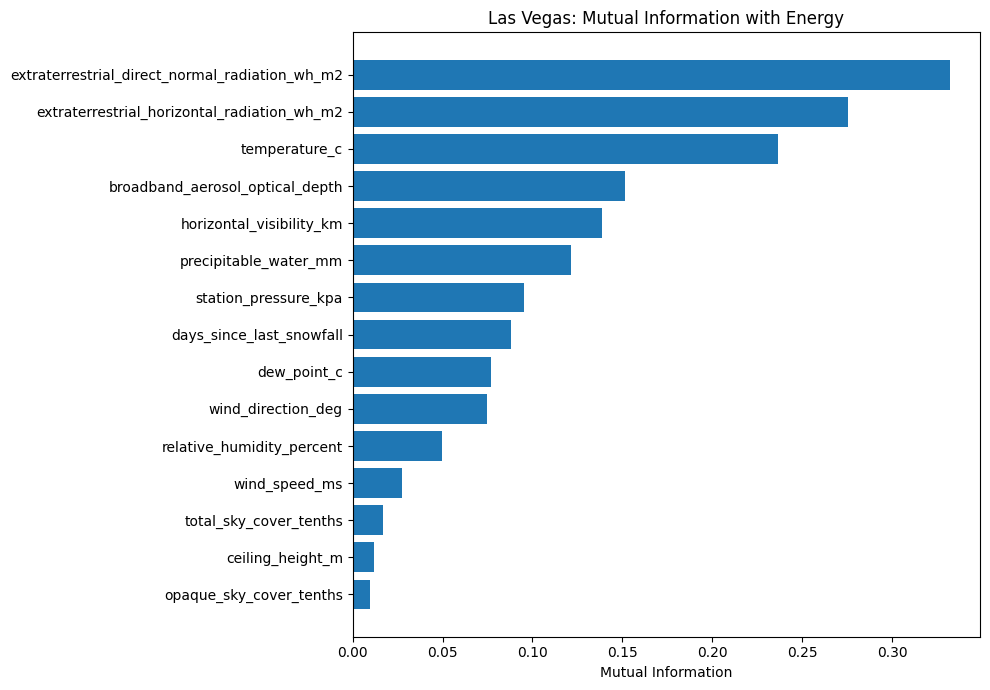


MUTUAL INFORMATION: Phoenix

Excluded completely empty columns:
  global_horizontal_radiation_wh_m2
  direct_normal_radiation_wh_m2
  diffuse_horizontal_radiation_wh_m2

Rows before cleaning: 70080
Rows used for MI: 70080
Features used: 19


,feature,mutual_information
1,extraterrestrial_direct_normal_radiation_wh_m2,0.298058
4,temperature_c,0.241837
0,extraterrestrial_horizontal_radiation_wh_m2,0.214788
15,broadband_aerosol_optical_depth,0.210641
5,dew_point_c,0.145401
14,precipitable_water_mm,0.141544
7,station_pressure_kpa,0.134738
10,horizontal_visibility_km,0.072189
17,days_since_last_snowfall,0.049873
6,relative_humidity_percent,0.032635


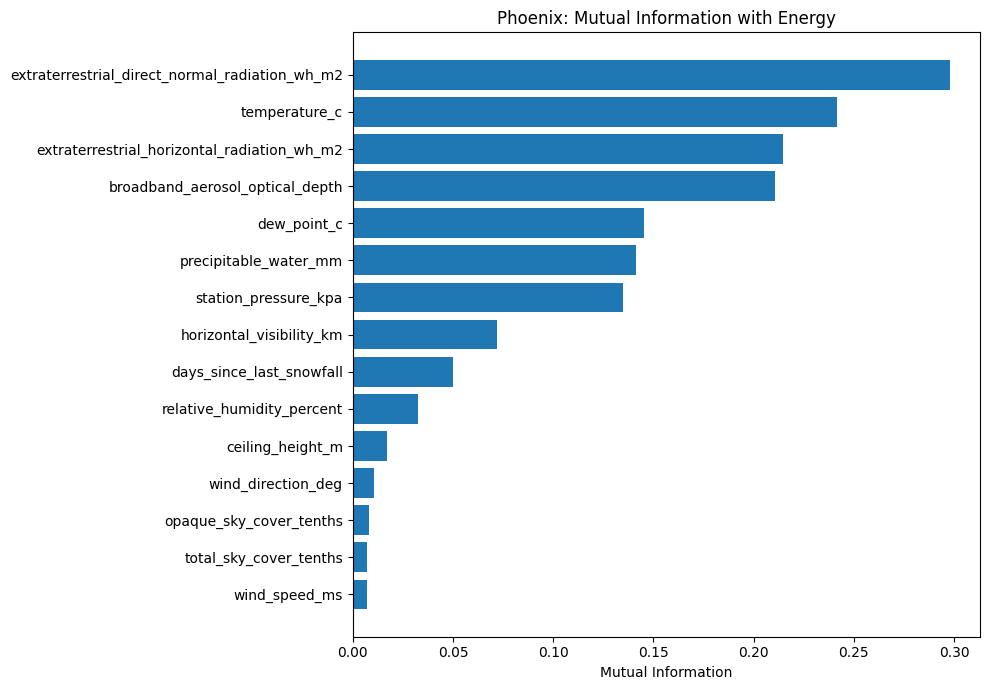

In [27]:
# 20. Mutual Information Analysis

from sklearn.feature_selection import mutual_info_regression

mi_reports = {}

print("=" * 80)
print("MUTUAL INFORMATION ANALYSIS")
print("=" * 80)

for city, df in merged.items():

    print(f"\n{'=' * 60}")
    print(f"MUTUAL INFORMATION: {city}")
    print(f"{'=' * 60}")

    # Only use weather variables that contain actual data
    cols = [
        c for c in weather_numeric[city]
        if df[c].notna().any()
        and df[c].notna().mean() > 0
    ]

    print("\nExcluded completely empty columns:")

    excluded = [
        c for c in weather_numeric[city]
        if c not in cols
    ]

    if excluded:
        for c in excluded:
            print(f"  {c}")
    else:
        print("  None")

    # Build MI dataset
    work = df[cols + ["hourly_load_mw"]].replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Remove only rows missing one of the selected variables
    work = work.dropna()

    print("\nRows before cleaning:", len(df))
    print("Rows used for MI:", len(work))
    print("Features used:", len(cols))

    if len(work) == 0:
        print("WARNING: No valid rows available. Skipping.")
        continue

    # Limit sample size for computational efficiency
    if len(work) > 100000:
        work = work.sample(
            100000,
            random_state=42
        )

    X = work[cols]
    y = work["hourly_load_mw"]

    mi = mutual_info_regression(
        X,
        y,
        random_state=42
    )

    report = pd.DataFrame({
        "feature": cols,
        "mutual_information": mi
    }).sort_values(
        "mutual_information",
        ascending=False
    )

    mi_reports[city] = report

    display(report)

    # Save report
    report.to_csv(
        TABLE_DIR /
        f"{city.lower().replace(' ', '_')}_mutual_information.csv",
        index=False
    )

    # Plot
    plot_data = report.head(15).sort_values(
        "mutual_information"
    )

    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    ax.barh(
        plot_data["feature"],
        plot_data["mutual_information"]
    )

    ax.set_title(
        f"{city}: Mutual Information with Energy"
    )

    ax.set_xlabel(
        "Mutual Information"
    )

    fig.tight_layout()

    fig.savefig(
        PLOT_DIR /
        f"{city.lower().replace(' ', '_')}_mutual_information.png",
        dpi=150
    )

    plt.show()

## 21. VIF / multicollinearity

VIF is especially important because derived variables can be mathematically redundant even when they each appear useful individually.


In [29]:
# 21. VIF / Multicollinearity Analysis

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_reports = {}

print("=" * 80)
print("VIF / MULTICOLLINEARITY ANALYSIS")
print("=" * 80)

for city, df in merged.items():

    print(f"\n{'=' * 60}")
    print(f"VIF ANALYSIS: {city}")
    print(f"{'=' * 60}")

    # Only use weather variables that actually contain data
    cols = [
        c for c in weather_numeric[city]
        if c in df.columns
        and df[c].notna().any()
    ]

    # Remove completely empty columns
    excluded = [
        c for c in weather_numeric[city]
        if c not in cols
    ]

    if excluded:
        print("\nExcluded completely empty columns:")
        for c in excluded:
            print(" ", c)

    # Prepare data
    work = df[cols].replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    print("\nRows before cleaning:", len(df))
    print("Rows used for VIF:", len(work))
    print("Candidate features:", len(cols))

    if len(work) == 0:
        print("WARNING: No valid rows available.")
        continue

    # Remove constant columns
    variable_cols = [
        c for c in cols
        if work[c].nunique() > 1
    ]

    removed_constant = [
        c for c in cols
        if c not in variable_cols
    ]

    if removed_constant:
        print("\nRemoved constant columns:")
        for c in removed_constant:
            print(" ", c)

    X = work[variable_cols].astype(float)

    # Calculate VIF
    rows = []

    for i, feature in enumerate(X.columns):

        try:
            vif_value = variance_inflation_factor(
                X.values,
                i
            )
        except Exception:
            vif_value = np.inf

        rows.append({
            "feature": feature,
            "VIF": float(vif_value)
        })

    # Explicitly create the DataFrame
    report = pd.DataFrame(
        rows,
        columns=["feature", "VIF"]
    )

    # Sort safely
    report = report.sort_values(
        by="VIF",
        ascending=False
    ).reset_index(drop=True)

    vif_reports[city] = report

    print("\nVIF RESULTS:")
    display(report)

    # Interpretation
    print("\nINTERPRETATION:")

    for _, row in report.iterrows():

        feature = row["feature"]
        vif = row["VIF"]

        if np.isinf(vif) or vif >= 10:
            level = "Very High"
        elif vif >= 5:
            level = "Moderate/High"
        elif vif >= 2.5:
            level = "Low/Moderate"
        else:
            level = "Low"

        print(
            f"{feature:45s} "
            f"VIF = {vif:10.3f}   {level}"
        )

    # Save report
    output_file = (
        TABLE_DIR /
        f"{city.lower().replace(' ', '_')}_weather_vif.csv"
    )

    report.to_csv(
        output_file,
        index=False
    )

    print("\nSaved:", output_file)

VIF / MULTICOLLINEARITY ANALYSIS

VIF ANALYSIS: Las Vegas

Excluded completely empty columns:
  global_horizontal_radiation_wh_m2
  direct_normal_radiation_wh_m2
  diffuse_horizontal_radiation_wh_m2

Rows before cleaning: 70080
Rows used for VIF: 70080
Candidate features: 19

Removed constant columns:
  snow_depth_cm

VIF RESULTS:


,feature,VIF
0,opaque_sky_cover_tenths,13.316662
1,temperature_c,11.485342
2,relative_humidity_percent,9.023701
3,dew_point_c,8.409792
4,total_sky_cover_tenths,6.487814
5,extraterrestrial_direct_normal_radiation_wh_m2,6.410639
6,ceiling_height_m,5.003479
7,horizontal_visibility_km,3.759323
8,extraterrestrial_horizontal_radiation_wh_m2,3.602064
9,precipitable_water_mm,2.792595



INTERPRETATION:
opaque_sky_cover_tenths                       VIF =     13.317   Very High
temperature_c                                 VIF =     11.485   Very High
relative_humidity_percent                     VIF =      9.024   Moderate/High
dew_point_c                                   VIF =      8.410   Moderate/High
total_sky_cover_tenths                        VIF =      6.488   Moderate/High
extraterrestrial_direct_normal_radiation_wh_m2 VIF =      6.411   Moderate/High
ceiling_height_m                              VIF =      5.003   Moderate/High
horizontal_visibility_km                      VIF =      3.759   Low/Moderate
extraterrestrial_horizontal_radiation_wh_m2   VIF =      3.602   Low/Moderate
precipitable_water_mm                         VIF =      2.793   Low/Moderate
station_pressure_kpa                          VIF =      1.798   Low
wind_speed_ms                                 VIF =      1.326   Low
days_since_last_snowfall                      VIF =      1.242   

,feature,VIF
0,dew_point_c,23.245276
1,precipitable_water_mm,16.142762
2,temperature_c,12.475470
3,opaque_sky_cover_tenths,11.388281
4,relative_humidity_percent,10.156394
5,ceiling_height_m,5.679371
6,total_sky_cover_tenths,4.367030
7,extraterrestrial_horizontal_radiation_wh_m2,3.635757
8,extraterrestrial_direct_normal_radiation_wh_m2,3.464075
9,station_pressure_kpa,1.950883



INTERPRETATION:
dew_point_c                                   VIF =     23.245   Very High
precipitable_water_mm                         VIF =     16.143   Very High
temperature_c                                 VIF =     12.475   Very High
opaque_sky_cover_tenths                       VIF =     11.388   Very High
relative_humidity_percent                     VIF =     10.156   Very High
ceiling_height_m                              VIF =      5.679   Moderate/High
total_sky_cover_tenths                        VIF =      4.367   Low/Moderate
extraterrestrial_horizontal_radiation_wh_m2   VIF =      3.636   Low/Moderate
extraterrestrial_direct_normal_radiation_wh_m2 VIF =      3.464   Low/Moderate
station_pressure_kpa                          VIF =      1.951   Low
horizontal_visibility_km                      VIF =      1.350   Low
wind_speed_ms                                 VIF =      1.298   Low
present_weather                               VIF =      1.244   Low
broadband_aerosol_

## 22. Explicit cross-parameter interaction analysis

This tests products such as temperature × moisture and temperature × pressure against energy. A strong interaction signal can indicate that the effect of one variable depends on another.


In [30]:
interaction_specs = [
    ("temperature_c", "dew_point_c"),
    ("temperature_c", "relative_humidity_percent"),
    ("temperature_c", "station_pressure_kpa"),
    ("temperature_c", "wind_speed_ms"),
    ("temperature_c", "precipitable_water_mm"),
    ("temperature_c", "broadband_aerosol_optical_depth"),
]

interaction_reports = {}

for city, df in merged.items():
    rows = []

    for a, b in interaction_specs:
        if a not in df.columns or b not in df.columns:
            continue

        work = df[[a, b, "hourly_load_mw"]].dropna()

        if len(work) < 100:
            continue

        product = work[a] * work[b]

        rows.append({
            "feature_a": a,
            "feature_b": b,
            "n": len(work),
            "interaction_pearson": product.corr(
                work["hourly_load_mw"]
            ),
            "interaction_spearman": product.corr(
                work["hourly_load_mw"],
                method="spearman"
            ),
        })

    report = pd.DataFrame(rows)
    interaction_reports[city] = report

    display(report)

    report.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_interaction_report.csv",
        index=False
    )


,feature_a,feature_b,n,interaction_pearson,interaction_spearman
0,temperature_c,dew_point_c,70080,0.330808,0.291986
1,temperature_c,relative_humidity_percent,70080,0.313684,0.242908
2,temperature_c,station_pressure_kpa,70080,0.365991,0.335161
3,temperature_c,wind_speed_ms,70080,0.232778,0.255257
4,temperature_c,precipitable_water_mm,70080,0.438253,0.407977
5,temperature_c,broadband_aerosol_optical_depth,70080,0.295804,0.321939


,feature_a,feature_b,n,interaction_pearson,interaction_spearman
0,temperature_c,dew_point_c,70080,0.522213,0.473759
1,temperature_c,relative_humidity_percent,70080,0.403333,0.331854
2,temperature_c,station_pressure_kpa,70080,0.447208,0.457740
3,temperature_c,wind_speed_ms,70080,0.220738,0.248308
4,temperature_c,precipitable_water_mm,70080,0.555658,0.531854
5,temperature_c,broadband_aerosol_optical_depth,70080,0.346849,0.433681


## 23. Temperature × moisture plots colored by energy

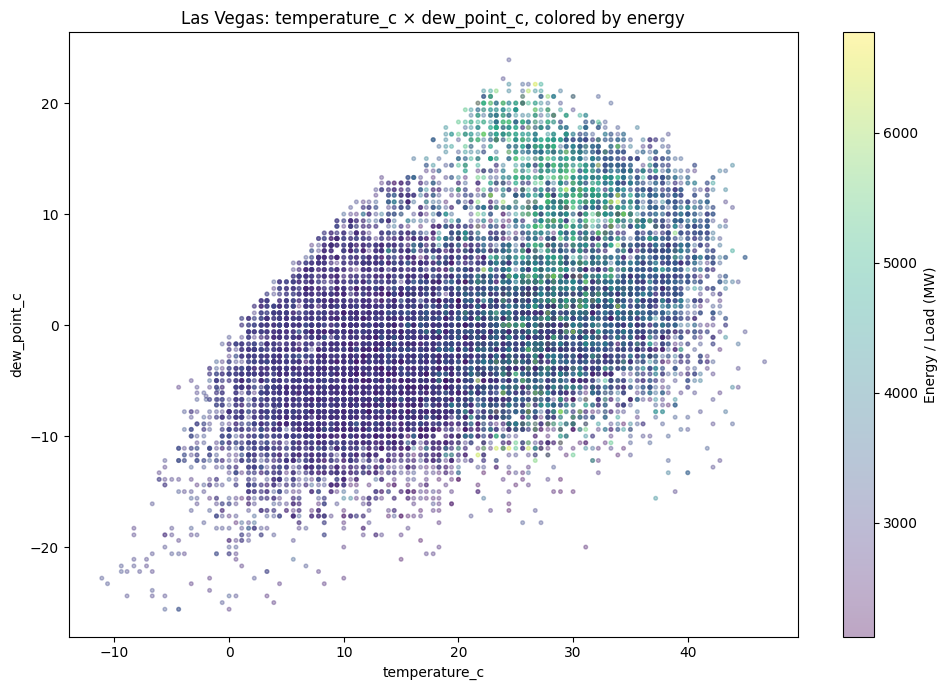

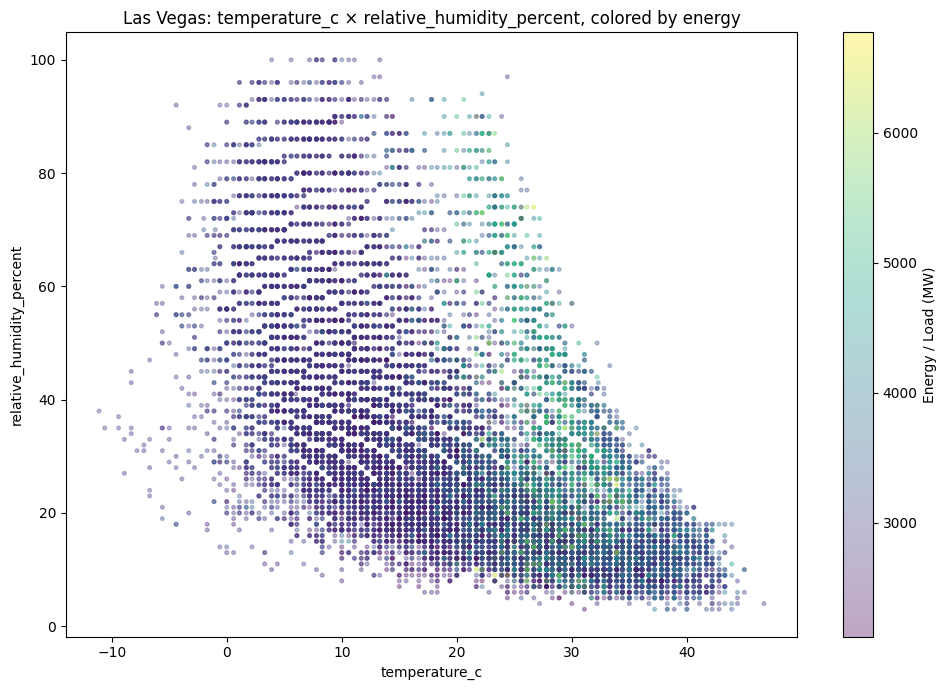

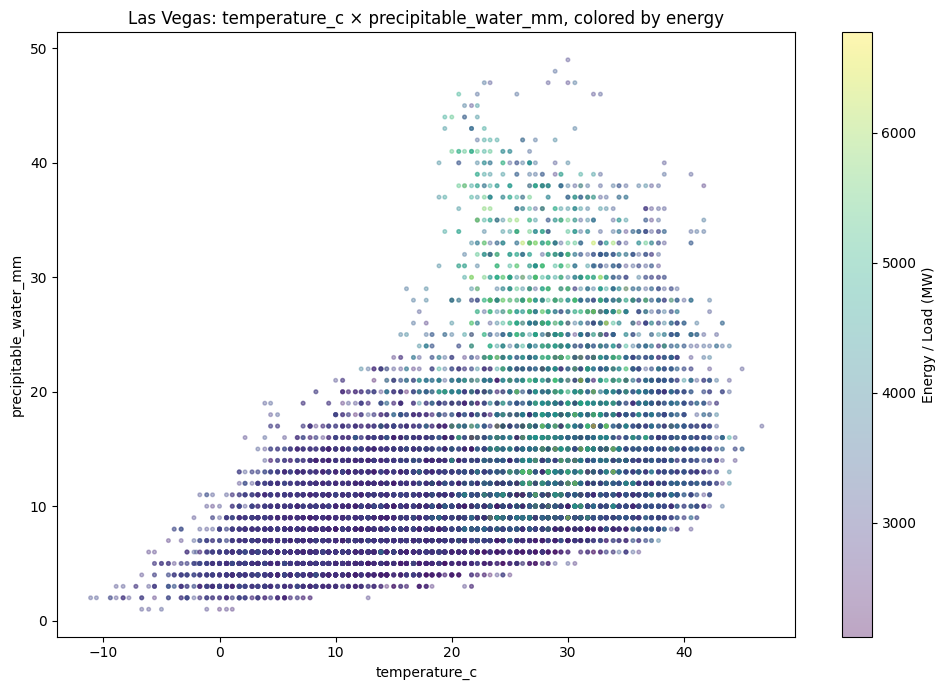

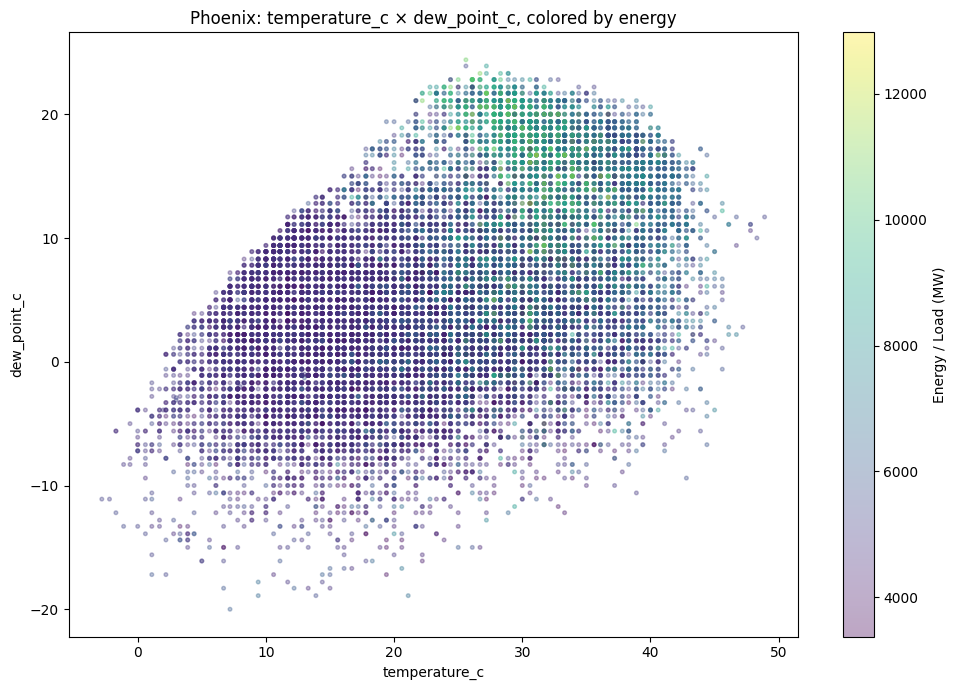

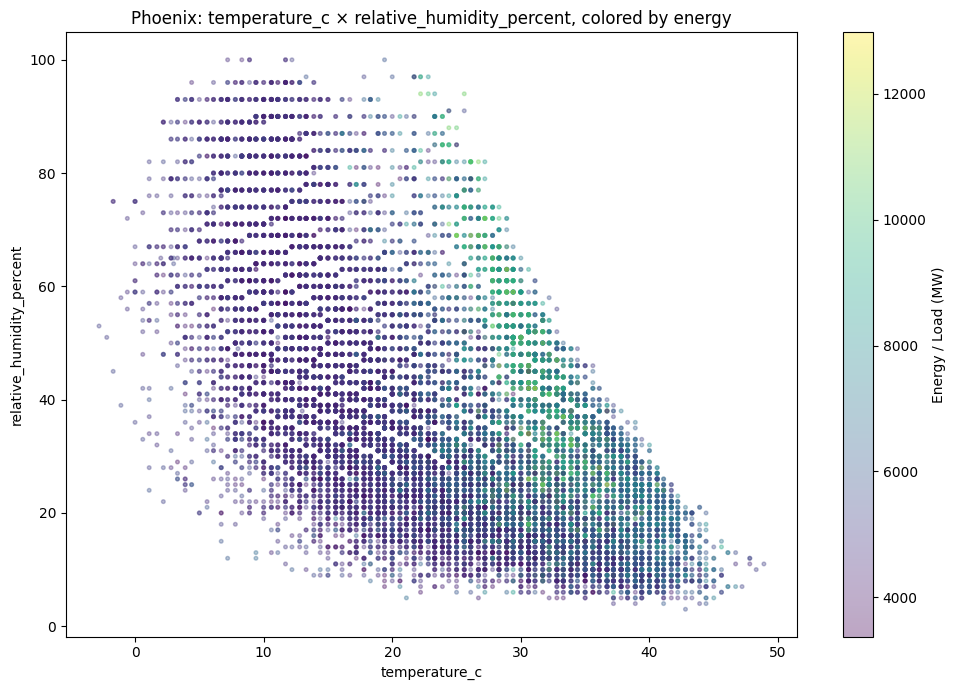

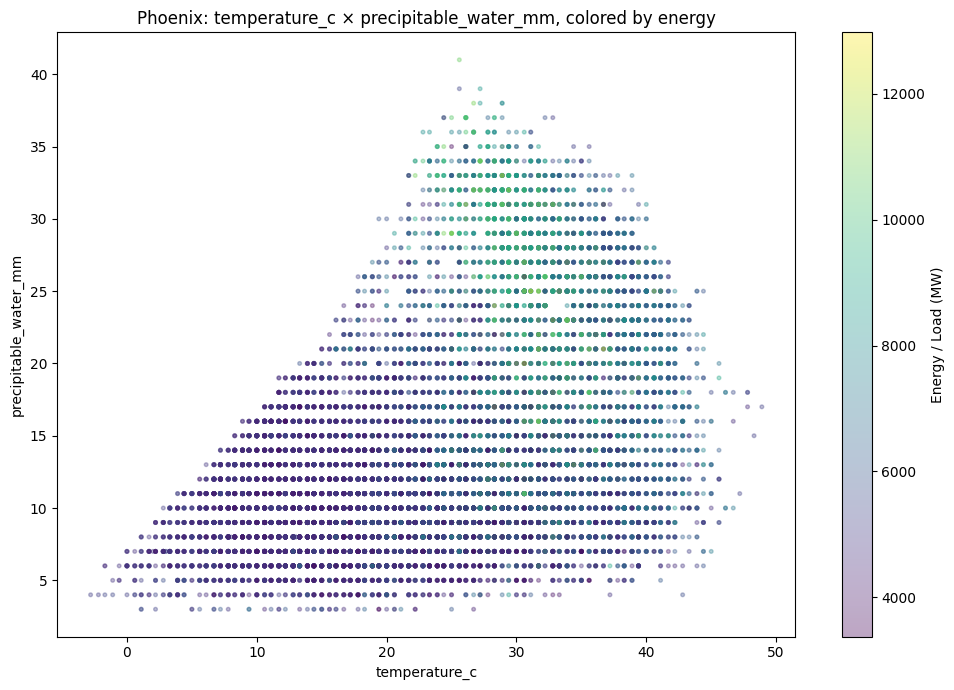

In [31]:
for city, df in merged.items():
    for xcol, ycol in [
        ("temperature_c", "dew_point_c"),
        ("temperature_c", "relative_humidity_percent"),
        ("temperature_c", "precipitable_water_mm"),
    ]:
        if xcol not in df.columns or ycol not in df.columns:
            continue

        work = df[[xcol, ycol, "hourly_load_mw"]].dropna()

        if len(work) > 20000:
            work = work.sample(20000, random_state=42)

        fig, ax = plt.subplots(figsize=(10, 7))
        sc = ax.scatter(
            work[xcol],
            work[ycol],
            c=work["hourly_load_mw"],
            s=7,
            alpha=0.35
        )

        ax.set_title(f"{city}: {xcol} × {ycol}, colored by energy")
        ax.set_xlabel(xcol)
        ax.set_ylabel(ycol)
        fig.colorbar(sc, ax=ax, label="Energy / Load (MW)")
        fig.tight_layout()
        fig.savefig(
            PLOT_DIR / f"{city.lower().replace(' ', '_')}_{xcol}_{ycol}_energy.png",
            dpi=150
        )
        plt.show()


## 24. Partial weather × energy correlations after calendar control

This removes linear effects associated with hour, day of week, month and year before correlating weather residuals with energy residuals.

This is a diagnostic of conditional association, not a causal estimate.


In [32]:
from sklearn.linear_model import LinearRegression

controls = ["hour", "day_of_week", "month", "year"]
partial_reports = {}

for city, df in merged.items():
    rows = []

    for feature in weather_numeric[city]:
        cols = controls + [feature, "hourly_load_mw"]

        subset = df[cols].replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        if len(subset) < 100:
            continue

        Cmat = subset[controls].astype(float)

        energy = subset["hourly_load_mw"].to_numpy(dtype=float)
        weather = subset[feature].to_numpy(dtype=float)

        energy_model = LinearRegression().fit(Cmat, energy)
        weather_model = LinearRegression().fit(Cmat, weather)

        energy_resid = energy - energy_model.predict(Cmat)
        weather_resid = weather - weather_model.predict(Cmat)

        rows.append({
            "feature": feature,
            "n": len(subset),
            "partial_pearson": np.corrcoef(
                weather_resid,
                energy_resid
            )[0, 1],
            "partial_spearman": pd.Series(weather_resid).corr(
                pd.Series(energy_resid),
                method="spearman"
            ),
        })

    report = pd.DataFrame(rows).sort_values(
        "partial_pearson",
        key=lambda s: s.abs(),
        ascending=False
    )

    partial_reports[city] = report
    display(report)

    report.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_partial_weather_energy.csv",
        index=False
    )


,feature,n,partial_pearson,partial_spearman
14,precipitable_water_mm,70080,0.432509,0.424025
0,extraterrestrial_horizontal_radiation_wh_m2,70080,-0.390154,-0.434552
1,extraterrestrial_direct_normal_radiation_wh_m2,70080,-0.389707,-0.499137
4,temperature_c,70080,0.364060,0.344517
5,dew_point_c,70080,0.344262,0.319410
10,horizontal_visibility_km,70080,-0.335113,-0.363152
7,station_pressure_kpa,70080,-0.276939,-0.290576
17,days_since_last_snowfall,70080,0.241341,0.297591
15,broadband_aerosol_optical_depth,70080,0.228925,0.251543
2,total_sky_cover_tenths,70080,-0.143331,-0.171818


,feature,n,partial_pearson,partial_spearman
14,precipitable_water_mm,70080,0.492804,0.459592
5,dew_point_c,70080,0.473425,0.456259
4,temperature_c,70080,0.457647,0.476696
7,station_pressure_kpa,70080,-0.397052,-0.433689
1,extraterrestrial_direct_normal_radiation_wh_m2,70080,-0.353401,-0.402499
0,extraterrestrial_horizontal_radiation_wh_m2,70080,-0.342190,-0.323204
15,broadband_aerosol_optical_depth,70080,0.305195,0.343326
17,days_since_last_snowfall,70080,0.153051,0.212861
6,relative_humidity_percent,70080,-0.085642,-0.076580
13,present_weather,70080,-0.083202,-0.042326


## 25. City-to-city comparison

,feature,Las_Vegas_Pearson,Phoenix_Pearson,Las_Vegas_Spearman,Phoenix_Spearman,Pearson_difference
9,horizontal_visibility_km,-0.333850,-0.037717,-0.376871,-0.046367,0.296133
19,total_sky_cover_tenths,-0.158818,-0.011950,-0.176179,-0.026403,0.146868
12,opaque_sky_cover_tenths,-0.107754,0.032868,-0.132378,0.022121,0.140622
3,dew_point_c,0.340421,0.466647,0.300419,0.427591,0.126226
17,station_pressure_kpa,-0.259415,-0.384658,-0.262415,-0.414952,-0.125243
1,ceiling_height_m,0.074193,-0.015507,0.083474,0.005921,-0.089700
18,temperature_c,0.367080,0.448761,0.337111,0.460750,0.081681
13,precipitable_water_mm,0.405468,0.486899,0.366755,0.421395,0.081430
2,days_since_last_snowfall,0.247627,0.182214,0.248923,0.240681,-0.065412
14,present_weather,-0.018500,-0.081570,0.034414,0.008605,-0.063070


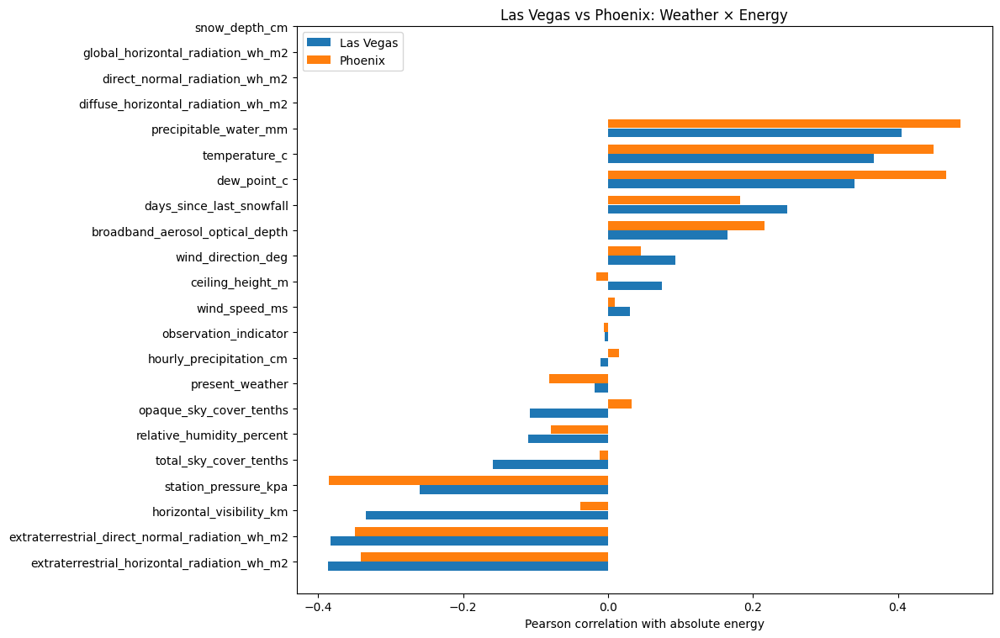

In [33]:
common_features = sorted(
    set(weather_numeric["Las Vegas"]) &
    set(weather_numeric["Phoenix"])
)

rows = []

for feature in common_features:
    lv = energy_corr_reports["Las Vegas"].set_index("feature").loc[feature]
    ph = energy_corr_reports["Phoenix"].set_index("feature").loc[feature]

    rows.append({
        "feature": feature,
        "Las_Vegas_Pearson": lv["pearson_energy"],
        "Phoenix_Pearson": ph["pearson_energy"],
        "Las_Vegas_Spearman": lv["spearman_energy"],
        "Phoenix_Spearman": ph["spearman_energy"],
        "Pearson_difference": (
            ph["pearson_energy"] - lv["pearson_energy"]
        ),
    })

city_comparison = pd.DataFrame(rows).sort_values(
    "Pearson_difference",
    key=lambda s: s.abs(),
    ascending=False
)

display(city_comparison)

city_comparison.to_csv(
    TABLE_DIR / "Las_Vegas_vs_Phoenix_weather_energy.csv",
    index=False
)

plot_df = city_comparison.sort_values("Las_Vegas_Pearson")

fig, ax = plt.subplots(figsize=(12, max(6, len(plot_df) * 0.35)))

y = np.arange(len(plot_df))

ax.barh(
    y - 0.18,
    plot_df["Las_Vegas_Pearson"],
    height=0.35,
    label="Las Vegas"
)

ax.barh(
    y + 0.18,
    plot_df["Phoenix_Pearson"],
    height=0.35,
    label="Phoenix"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["feature"])
ax.set_xlabel("Pearson correlation with absolute energy")
ax.set_title("Las Vegas vs Phoenix: Weather × Energy")
ax.legend()

fig.tight_layout()
fig.savefig(
    PLOT_DIR / "Las_Vegas_vs_Phoenix_weather_energy.png",
    dpi=160
)
plt.show()


## 26. Final diagnostic feature ranking

In [34]:
diagnostic_reports = {}

for city in merged:
    report = energy_corr_reports[city].copy()

    if city in mi_reports:
        report = report.merge(
            mi_reports[city],
            on="feature",
            how="left"
        )
    else:
        report["mutual_information"] = np.nan

    if city in vif_reports:
        report = report.merge(
            vif_reports[city],
            on="feature",
            how="left"
        )
    else:
        report["VIF"] = np.nan

    if city in partial_reports:
        partial_map = partial_reports[city].set_index("feature")
        report["partial_pearson"] = report["feature"].map(
            partial_map["partial_pearson"]
        )
    else:
        report["partial_pearson"] = np.nan

    report["abs_partial_pearson"] = report["partial_pearson"].abs()

    report["diagnostic_signal_score"] = (
        report["abs_pearson"].fillna(0)
        + report["abs_spearman"].fillna(0)
        + report["mutual_information"].fillna(0)
        + report["abs_partial_pearson"].fillna(0)
    )

    report = report.sort_values(
        "diagnostic_signal_score",
        ascending=False
    )

    diagnostic_reports[city] = report

    display(report)

    report.to_csv(
        TABLE_DIR / f"{city.lower().replace(' ', '_')}_diagnostic_feature_ranking.csv",
        index=False
    )


,feature,pearson_energy,spearman_energy,abs_pearson,abs_spearman,mutual_information,VIF,partial_pearson,abs_partial_pearson,diagnostic_signal_score
2,extraterrestrial_direct_normal_radiation_wh_m2,-0.382891,-0.537486,0.382891,0.537486,0.332340,6.410639,-0.389707,0.389707,1.642424
1,extraterrestrial_horizontal_radiation_wh_m2,-0.385907,-0.443030,0.385907,0.443030,0.275630,3.602064,-0.390154,0.390154,1.494722
0,precipitable_water_mm,0.405468,0.366755,0.405468,0.366755,0.121427,2.792595,0.432509,0.432509,1.326160
3,temperature_c,0.367080,0.337111,0.367080,0.337111,0.236763,11.485342,0.364060,0.364060,1.305014
5,horizontal_visibility_km,-0.333850,-0.376871,0.333850,0.376871,0.138948,3.759323,-0.335113,0.335113,1.184783
4,dew_point_c,0.340421,0.300419,0.340421,0.300419,0.076763,8.409792,0.344262,0.344262,1.061864
6,station_pressure_kpa,-0.259415,-0.262415,0.259415,0.262415,0.095039,1.798175,-0.276939,0.276939,0.893807
7,days_since_last_snowfall,0.247627,0.248923,0.247627,0.248923,0.088325,1.241725,0.241341,0.241341,0.826215
8,broadband_aerosol_optical_depth,0.164891,0.188451,0.164891,0.188451,0.151678,1.158548,0.228925,0.228925,0.733945
9,total_sky_cover_tenths,-0.158818,-0.176179,0.158818,0.176179,0.016614,6.487814,-0.143331,0.143331,0.494942


,feature,pearson_energy,spearman_energy,abs_pearson,abs_spearman,mutual_information,VIF,partial_pearson,abs_partial_pearson,diagnostic_signal_score
2,temperature_c,0.448761,0.460750,0.448761,0.460750,0.241837,12.475470,0.457647,0.457647,1.608995
0,precipitable_water_mm,0.486899,0.421395,0.486899,0.421395,0.141544,16.142762,0.492804,0.492804,1.542642
1,dew_point_c,0.466647,0.427591,0.466647,0.427591,0.145401,23.245276,0.473425,0.473425,1.513064
4,extraterrestrial_direct_normal_radiation_wh_m2,-0.349476,-0.435351,0.349476,0.435351,0.298058,3.464075,-0.353401,0.353401,1.436286
3,station_pressure_kpa,-0.384658,-0.414952,0.384658,0.414952,0.134738,1.950883,-0.397052,0.397052,1.331401
5,extraterrestrial_horizontal_radiation_wh_m2,-0.340589,-0.341691,0.340589,0.341691,0.214788,3.635757,-0.342190,0.342190,1.239257
6,broadband_aerosol_optical_depth,0.215728,0.281532,0.215728,0.281532,0.210641,1.237559,0.305195,0.305195,1.013096
7,days_since_last_snowfall,0.182214,0.240681,0.182214,0.240681,0.049873,1.112872,0.153051,0.153051,0.625820
9,relative_humidity_percent,-0.079218,-0.070958,0.079218,0.070958,0.032635,10.156394,-0.085642,0.085642,0.268454
11,horizontal_visibility_km,-0.037717,-0.046367,0.037717,0.046367,0.072189,1.350139,-0.035496,0.035496,0.191769


# 27. Final analysis checklist

Use the generated tables and plots to answer:

### Weather × weather
* Which variables are highly correlated?
* Which variables are effectively duplicates?
* Which variables have high VIF?
* Which relationships are nonlinear?

### Weather × energy
* Which variables have the strongest Pearson relationships?
* Which have stronger Spearman than Pearson relationships?
* Which have meaningful mutual information despite weak Pearson correlation?
* Which relationships survive hour/month/day/year controls?

### Interactions
* Does temperature behave differently at different moisture levels?
* Does temperature response change by season?
* Does the effect of weather vary by hour?
* Are aerosol, pressure, wind or precipitation acting as independent signals or proxies for other weather states?

### City differences
* Which weather-energy relationships are stable between Las Vegas and Phoenix?
* Which relationships differ substantially?
* Are the candidate features physically meaningful and statistically defensible?

The correct next model should be based on this evidence rather than raw correlation alone.


# 28. Output locations

All diagnostic tables are saved to:

`LV_Phoenix_Weather_Energy_Analysis/tables`

All plots are saved to:

`LV_Phoenix_Weather_Energy_Analysis/plots`

The original CSV files are never modified.
